# WaDi Dataset Exploration (EDA) — v2
**50.020 Network Security – Water Distribution System (WaDi)**

Files: `WADI_14days_new.csv` (normal operation) and `WADI_attackdataLABLE.csv` (attack data with labels).

### What changed from v1
| v1 problem | Effect in v1 output | v2 fix |
|---|---|---|
| Attack CSV's real header is on **line 2** | Attack columns came out as `'0'…'130'`, every dtype was `str` | Loader finds the header line automatically |
| `Time` is Excel's `mm:ss.0` format, so the **hour is lost** | Timestamps repeat every hour, 57% / 100% unparsed, and `sort_values("Timestamp")` scrambles the time-series plots | Timestamps rebuilt from `Row` (1 Hz) + the date roll-over, then checked against the `mm:ss` in `Time` |
| Label column never found | Sections 12–13 printed nothing | Label column renamed to `ATTACK` (1 = attack, 0 = normal) |
| No common column names | Section 8 (normal vs attack) silently drew **zero** plots | Fixed by the loader; sensors now ranked by how far they shift |
| Duplicate check includes `Row` | Can never find a duplicate | Checks sensor values only |
| `sep=None, engine="python"` | Very slow on 785k rows, ~790 MB in RAM | Separator sniffed once, C parser, float32 |
| Histograms / heatmap / rolling use "first N columns" | Several are constant or all-NaN columns, so the plots carry no information | Uses only informative sensors, chosen by variance and ranking |

Sections **A–L** at the end are new: they look at relationships between sensors and patterns in the data.

## 1. Imports, paths and settings

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import csv, re, json, warnings
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

NORMAL_FILE = Path("dataset/WADI_14days_new.csv")
ATTACK_FILE = Path("dataset/WADI_attackdataLABLE.csv")

# Heavy analyses (correlation, lags, PCA) run on a resampled copy. 10 s keeps
# dynamics (pump cycles, valve moves) and is ~10x lighter than 1 Hz.
RESAMPLE = "10s"

print("Normal file exists:", NORMAL_FILE.exists())
print("Attack file exists:", ATTACK_FILE.exists())

Normal file exists: True
Attack file exists: True


## 2. Load the CSV files (fixed)
The attack file has an extra line above the real header. The loader looks through the first lines for the one containing `Row` and `Date`, sniffs the separator once, then uses the fast C parser. Fully empty trailing rows are dropped.

In [ ]:
def load_wadi_csv(path, max_scan=10):
    for enc in ["utf-8-sig", "cp1252", "latin1"]:
        try:
            with open(path, encoding=enc) as f:
                head = [next(f) for _ in range(max_scan)]
            break
        except UnicodeDecodeError:
            continue
    header_idx = next(i for i, line in enumerate(head) if "Row" in line and "Date" in line)
    sep = csv.Sniffer().sniff(head[header_idx], delimiters=",\t;").delimiter
    df = pd.read_csv(path, sep=sep, skiprows=header_idx, encoding=enc, low_memory=False)
    df.columns = df.columns.astype(str).str.strip()
    df = df.dropna(how="all")                                   # trailing blank rows
    # downcast numerics to float32 to halve memory
    for c in df.columns:
        if c in ("Date", "Time"):
            continue
        df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")
    # footer / partially empty rows (the attack file has a couple): no Row number or no Date
    bad = df["Row"].isna() | df["Date"].isna()
    if bad.any():
        print(f"   dropping {int(bad.sum())} row(s) without Row/Date at index {df.index[bad].tolist()[:5]}")
        df = df[~bad].reset_index(drop=True)
    print(f"{path.name}: header on line {header_idx + 1}, sep={sep!r}, shape={df.shape}, "
          f"{df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
    return df

normal_df = load_wadi_csv(NORMAL_FILE)
attack_df = load_wadi_csv(ATTACK_FILE)
display(attack_df.iloc[:3, :8])

WADI_14days_new.csv: header on line 1, sep=',', shape=(784571, 130), 426 MB
   dropping 2 row(s) without Row/Date at index [172801, 172802]
WADI_attackdataLABLE.csv: header on line 2, sep=',', shape=(172801, 131), 95 MB


,Row,Date,Time,1_AIT_001_PV,1_AIT_002_PV,1_AIT_003_PV,1_AIT_004_PV,1_AIT_005_PV
0,1.0,10/9/17,00:00.0,164.210007,0.529486,11.9972,482.480011,0.331167
1,2.0,10/9/17,00:01.0,164.210007,0.529486,11.9972,482.480011,0.331167
2,3.0,10/9/17,00:02.0,164.210007,0.529486,11.9972,482.480011,0.331167


## 3. Label column
WaDi convention: `1 = No Attack`, `-1 = Attack`. It is converted to `ATTACK` (1 = attack, 0 = normal) so it reads like any binary target. Labels are only for evaluation, never a model input.

In [ ]:
label_col = next(c for c in attack_df.columns if "attack" in c.lower() or "label" in c.lower())
print("Label column:", repr(label_col))
print(attack_df[label_col].value_counts(dropna=False))

attack_df["ATTACK"] = (attack_df[label_col] == -1).astype(int)
attack_df = attack_df.drop(columns=[label_col])
normal_df["ATTACK"] = 0
print(f"Attack rows: {attack_df.ATTACK.sum():,} / {len(attack_df):,} ({attack_df.ATTACK.mean():.2%})")

Label column: 'Attack LABLE (1:No Attack, -1:Attack)'
Attack LABLE (1:No Attack, -1:Attack)
 1.0    162824
-1.0      9977
Name: count, dtype: int64
Attack rows: 9,977 / 172,801 (5.77%)


## 4. Timestamps (fixed)
`Time` looks like `00:00.0`, `00:01.0`, … This is Excel's **`mm:ss.0`** display format, so the CSV was saved after Excel dropped the **hour**. Combining `Date + "00:" + Time` therefore gives timestamps that repeat every hour. That is why v1's coverage was poor and its time-sorted plots were scrambled.

WaDi is sampled at 1 Hz, so the timestamp is rebuilt from `Row`, anchored on the row where `Date` rolls over to the next day (that row is 00:00:00). The cell then **checks** that the rebuilt minute:second matches `Time` on every row. Any mismatch means rows were removed (gaps), and they are reported.

In [ ]:
def rebuild_timestamp(df, name):
    df = df.copy()
    date = pd.to_datetime(df["Date"], format="mixed", errors="coerce").dt.normalize()
    row = df["Row"].astype("int64").to_numpy()

    roll = np.flatnonzero(date.to_numpy()[1:] != date.to_numpy()[:-1])
    if len(roll):                                    # first row of the 2nd day = midnight
        i = roll[0] + 1
        anchor_time, anchor_row = date.iloc[i], row[i]
    else:                                            # single-day file: fall back to mm:ss of row 0
        mm, ss = map(float, str(df["Time"].iloc[0]).split(":"))
        anchor_time, anchor_row = date.iloc[0] + pd.Timedelta(minutes=mm, seconds=ss), row[0]

    df["Timestamp"] = anchor_time + pd.to_timedelta(row - anchor_row, unit="s")

    # --- validation: rebuilt mm:ss must equal the Time column ---
    t = df["Time"].astype(str).str.extract(r"^(\d{1,2}):(\d{2})")
    mmss_file = t[0].astype(float) * 60 + t[1].astype(float)
    mmss_rebuilt = df["Timestamp"].dt.minute * 60 + df["Timestamp"].dt.second
    match = (mmss_file == mmss_rebuilt).mean()
    date_match = (df["Timestamp"].dt.normalize() == date).mean()
    gaps = df["Timestamp"].diff().dt.total_seconds().value_counts().head(3)
    print(f"{name}: {df.Timestamp.iloc[0]} -> {df.Timestamp.iloc[-1]} "
          f"({(df.Timestamp.iloc[-1] - df.Timestamp.iloc[0]).total_seconds() / 86400:.2f} days)")
    print(f"   mm:ss agreement {match:.4%} | date agreement {date_match:.4%} | step sizes (s): {dict(gaps)}")
    if match < 0.999:
        print("   WARNING: rows are not contiguous 1 Hz - inspect where the mismatch starts:")
        print(df.loc[mmss_file != mmss_rebuilt, ["Row", "Date", "Time", "Timestamp"]].head())
    return df.set_index("Timestamp")

normal_df = rebuild_timestamp(normal_df, "NORMAL")
attack_df = rebuild_timestamp(attack_df, "ATTACK")

NORMAL: 2017-09-25 18:00:00 -> 2017-10-07 21:16:10 (12.14 days)
   mm:ss agreement 100.0000% | date agreement 100.0000% | step sizes (s): {1.0: np.int64(784569), 264001.0: np.int64(1)}
ATTACK: 2017-10-09 18:00:00 -> 2017-10-11 18:00:00 (2.00 days)
   mm:ss agreement 100.0000% | date agreement 100.0000% | step sizes (s): {1.0: np.int64(172800)}


## 5. Column alignment and feature hygiene
This sorts columns into four groups, which is useful for deciding what the models use:
* **all-NaN**: drop.
* **constant in normal**: a model trained on normal data cannot learn anything from these, and they break `StandardScaler` (std = 0).
* **constant in normal but varying in attack**: important. The attacker touched them. A *rule* catches these perfectly, but an LSTM-AE or Isolation Forest fitted on scaled normal data may ignore them.
* **informative**: the feature set for the models.

In [ ]:
META = {"Row", "Date", "Time", "ATTACK"}
common = [c for c in normal_df.columns if c in attack_df.columns and c not in META]
print("Only in normal:", sorted(set(normal_df.columns) - set(attack_df.columns) - META))
print("Only in attack:", sorted(set(attack_df.columns) - set(normal_df.columns) - META))

all_nan = [c for c in common if normal_df[c].isna().all()]
nunique_n = normal_df[common].nunique()
nunique_a = attack_df[common].nunique()
const_normal = [c for c in common if c not in all_nan and nunique_n[c] <= 1]
const_but_attacked = [c for c in const_normal if nunique_a[c] > 1]
FEATURES = [c for c in common if c not in all_nan and c not in const_normal]

print(f"\nAll-NaN ({len(all_nan)}):", all_nan)
print(f"Constant in normal ({len(const_normal)})")
print(f"Constant in normal BUT varying in attack ({len(const_but_attacked)}):", const_but_attacked)
for c in const_but_attacked:
    ct = pd.crosstab(attack_df[c], attack_df["ATTACK"])
    print(f"   {c}: values per label ->", ct.to_dict())
print(f"\nInformative features for modelling: {len(FEATURES)}")

print("\nDuplicate sensor rows (excl. Row/Date/Time):",
      int(normal_df[FEATURES].duplicated().sum()), "normal |",
      int(attack_df[FEATURES].duplicated().sum()), "attack")
print("Remaining NaNs in features:",
      int(normal_df[FEATURES].isna().sum().sum()), "normal |",
      int(attack_df[FEATURES].isna().sum().sum()), "attack  -> ffill before modelling")
normal_df[FEATURES] = normal_df[FEATURES].ffill().bfill()
attack_df[FEATURES] = attack_df[FEATURES].ffill().bfill()

Only in normal: []
Only in attack: []

All-NaN (4): ['2_LS_001_AL', '2_LS_002_AL', '2_P_001_STATUS', '2_P_002_STATUS']
Constant in normal (30)
Constant in normal BUT varying in attack (5): ['1_MV_002_STATUS', '1_MV_003_STATUS', '1_P_006_STATUS', '2_MCV_007_CO', '2_PIC_003_SP']
   1_MV_002_STATUS: values per label -> {0: {0.0: 6, 1.0: 162631, 2.0: 187}, 1: {0.0: 44, 1.0: 8633, 2.0: 1300}}
   1_MV_003_STATUS: values per label -> {0: {0.0: 11, 1.0: 162631, 2.0: 182}, 1: {0.0: 44, 1.0: 8633, 2.0: 1300}}
   1_P_006_STATUS: values per label -> {0: {1.0: 162817, 2.0: 7}, 1: {1.0: 9900, 2.0: 77}}
   2_MCV_007_CO: values per label -> {0: {0.0: 162808, 10.0: 11, 20.0: 1, 30.0: 0, 40.0: 0, 50.0: 0, 60.0: 0, 70.0: 0, 80.0: 0, 90.0: 0, 100.0: 4}, 1: {0.0: 8449, 10.0: 35, 20.0: 123, 30.0: 118, 40.0: 125, 50.0: 135, 60.0: 140, 70.0: 73, 80.0: 40, 90.0: 40, 100.0: 699}}
   2_PIC_003_SP: values per label -> {0: {0.25: 136, 0.5: 56, 1.0: 162632}, 1: {0.25: 0, 0.5: 0, 1.0: 9977}}

Informative features fo

## 6. Sensor taxonomy: stage × instrument type
Tag format: `<stage>_<type>_<id>_<attribute>`. Stage 1 = supply and storage, 2 = elevated reservoir and distribution (2A/2B = consumer-side analysers), 3 = return. Types: AIT analyser, FIT flow, LT level, PIT pressure, DPIT diff. pressure, FIC flow controller (PV/SP/CO), MV/SV motor/solenoid valve, P pump, MCV modulating valve, LS level switch, FQ flow totaliser.

In [ ]:
def parse_tag(c):
    m = re.match(r"^(\w+?)_([A-Z]+)_(\d+)_([A-Z]+)$", c)
    return m.groups() if m else ("plant", c, "", "")

tax = pd.DataFrame([parse_tag(c) for c in FEATURES], index=FEATURES,
                   columns=["stage", "type", "id", "attr"])
tax["kind"] = np.where(tax.attr.isin(["STATUS", "AL", "AH"]), "discrete", "continuous")
display(pd.crosstab(tax.type, tax.stage, margins=True))

CONT = tax.index[tax.kind == "continuous"].tolist()
DISC = tax.index[tax.kind == "discrete"].tolist()
print(f"{len(CONT)} continuous, {len(DISC)} discrete informative features")

# Totalisers / counters only ever go up (e.g. 2_FQ_x01 flow totals). Their absolute value depends on how long
# the plant has run, not on its state, so they are trivially "anomalous" in the attack file and
# correlate with everything that trends. Use their rate of change instead.
_d = normal_df[CONT].iloc[::10].diff().dropna()
TOTALISERS = [c for c in CONT if (_d[c] >= -1e-6).mean() > 0.995 and normal_df[c].nunique() > 20]
print("Monotonic totalisers (use .diff() or drop for modelling):", TOTALISERS)
CONT_DYN = [c for c in CONT if c not in TOTALISERS]         # continuous sensors that describe plant state
MODEL_FEATURES = [c for c in FEATURES if c not in TOTALISERS]

# Resampled copies used for the heavier analyses below
n_rs = normal_df[FEATURES].resample(RESAMPLE).mean()
a_rs = attack_df[FEATURES + ["ATTACK"]].resample(RESAMPLE).agg({**{c: "mean" for c in FEATURES}, "ATTACK": "max"})
# The normal file has time gaps (unstable periods were removed), which resample() turns into empty NaN bins
_gaps = int(n_rs.isna().all(axis=1).sum())
n_rs = n_rs.dropna(how="all").ffill().bfill()
a_rs = a_rs.dropna(how="all", subset=FEATURES).ffill().bfill()
print(f"Resampled: {n_rs.shape} {a_rs.shape}  (removed {_gaps} empty bins from gaps in the normal file)")

stage,1,2,2A,2B,3,plant,All
type,,,,,,,
AIT,5,0,4,4,5,0,18
DPIT,0,1,0,0,0,0,1
FIC,0,18,0,0,0,0,18
FIT,1,3,0,0,1,0,5
FQ,0,6,0,0,0,0,6
LEAK_DIFF_PRESSURE,0,0,0,0,0,1,1
LS,0,12,0,0,0,0,12
LT,1,2,0,0,1,0,4
MCV,0,6,0,0,0,0,6


67 continuous, 26 discrete informative features
Monotonic totalisers (use .diff() or drop for modelling): ['2_FIC_101_SP', '2_FIC_201_SP', '2_FIC_301_SP', '2_FIC_401_SP', '2_FIC_501_SP', '2_FIC_601_SP', '2A_AIT_002_PV']
Resampled: (78459, 93) (17281, 94)  (removed 26399 empty bins from gaps in the normal file)


## 7. Sensor distributions (informative continuous sensors only)

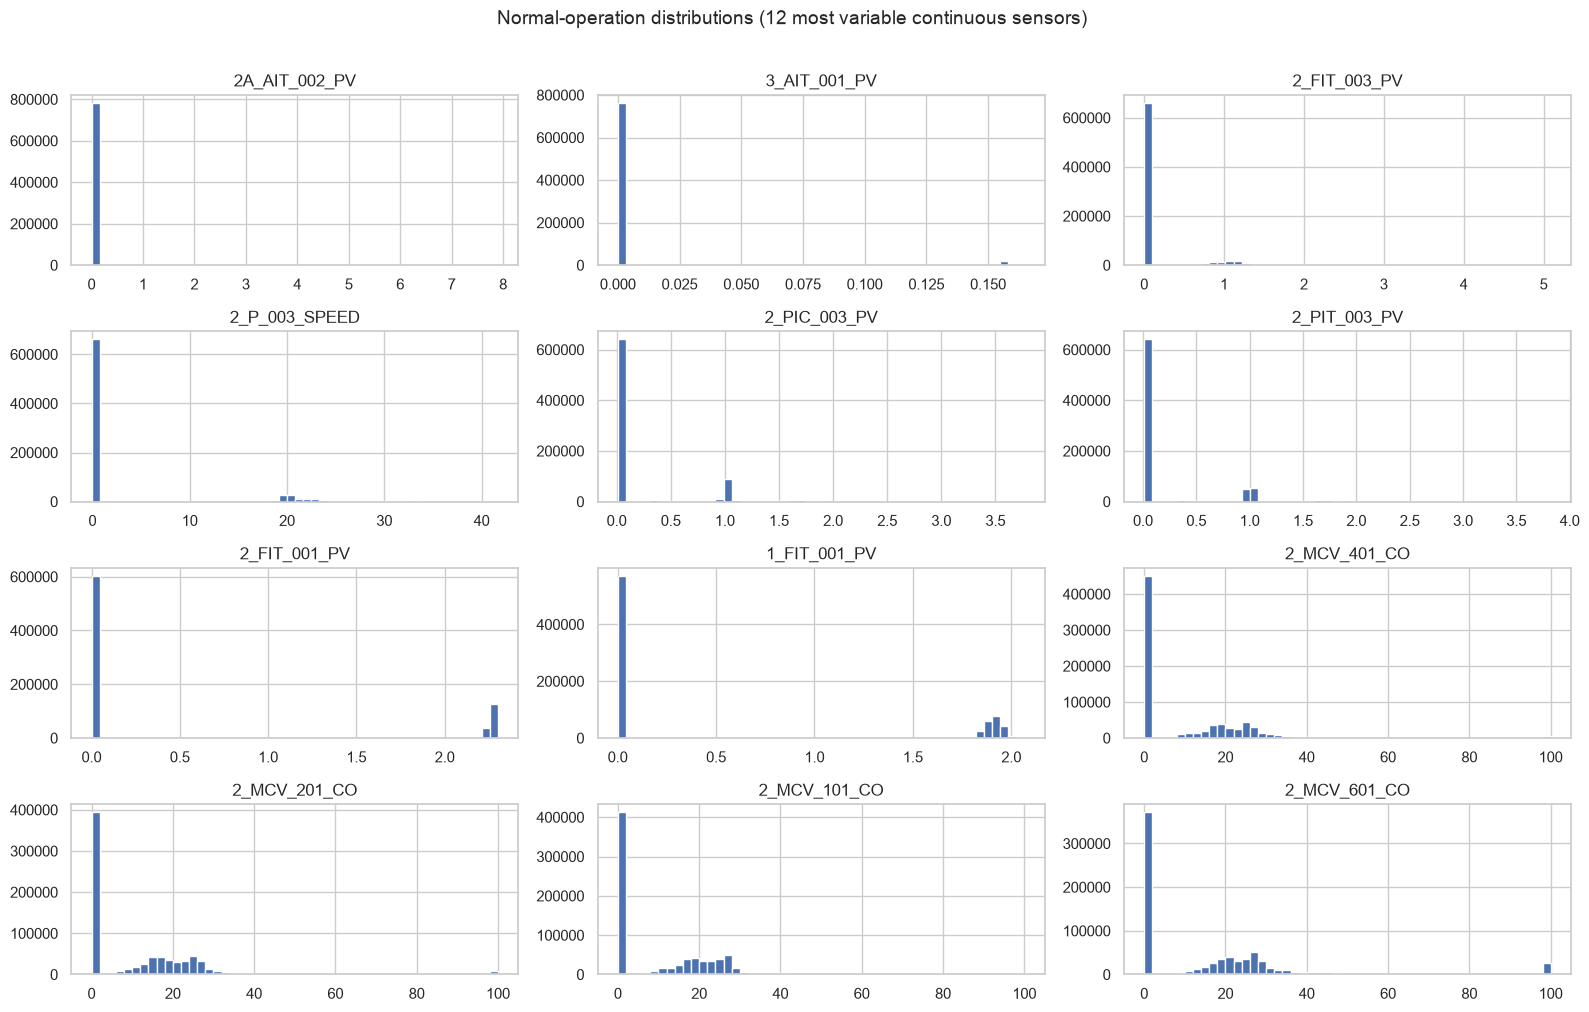

Bimodality coefficient > 0.555 suggests 2+ operating regimes:


,BC
3_AIT_001_PV,1.000
1_FIT_001_PV,0.998
2_FIT_001_PV,0.992
3_AIT_002_PV,0.983
2_P_003_SPEED,0.943
2_FIC_301_CO,0.934
2_FIC_501_CO,0.932
2_FIC_601_CO,0.930
2_FIC_201_CO,0.917
2_FIC_101_CO,0.904


In [ ]:
cv = (normal_df[CONT].std() / normal_df[CONT].mean().abs().replace(0, np.nan)).sort_values(ascending=False)
hist_cols = cv.index[:12].tolist()            # most variable sensors, not "first 12 columns"
normal_df[hist_cols].hist(bins=50, figsize=(16, 10), layout=(4, 3))
plt.suptitle("Normal-operation distributions (12 most variable continuous sensors)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

# Multi-modality hint: bimodal sensors usually follow an actuator state (pump on/off)
bimod = {}
for c in CONT:
    x = n_rs[c].dropna().to_numpy()
    if x.std() > 0:
        n = len(x); g = stats.skew(x); k = stats.kurtosis(x)
        bimod[c] = (g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3)))
print("Bimodality coefficient > 0.555 suggests 2+ operating regimes:")
display(pd.Series(bimod).sort_values(ascending=False).head(15).round(3).to_frame("BC"))

## 8. Normal vs attack: which sensors shift most? (fixed, ranked)
v1 drew 0 plots because no columns matched. Here every sensor gets two **Kolmogorov–Smirnov** statistics:
* `KS_attack`: normal file vs attack rows, i.e. how visible the attacks are in that sensor's marginal distribution.
* `KS_drift`: normal file vs the **non-attack** rows of the attack file. A high value means the plant was simply operating differently two weeks later. That causes **false positives** for any model trained on the normal file and is worth knowing before blaming the LSTM-AE.

,KS_attack,KS_drift,attack_minus_drift
1_AIT_003_PV,0.960000,0.921000,0.039000
2B_AIT_004_PV,0.898000,0.795000,0.103000
1_AIT_004_PV,0.776000,0.736000,0.040000
2A_AIT_004_PV,0.890000,0.680000,0.210000
2B_AIT_002_PV,0.393000,0.555000,-0.161000
2B_AIT_003_PV,0.616000,0.532000,0.084000
1_AIT_001_PV,0.534000,0.505000,0.029000
2A_AIT_001_PV,0.464000,0.461000,0.003000
3_AIT_005_PV,0.354000,0.431000,-0.077000
2B_AIT_001_PV,0.323000,0.393000,-0.070000


,KS_attack,KS_drift,attack_minus_drift
2_FIC_501_SP,0.617000,0.055000,0.561000
1_FIT_001_PV,0.498000,0.029000,0.469000
TOTAL_CONS_REQUIRED_FLOW,0.461000,0.042000,0.419000
1_P_001_STATUS,0.422000,0.017000,0.405000
1_P_003_STATUS,0.419000,0.017000,0.402000
1_MV_001_STATUS,0.404000,0.017000,0.387000
2_P_004_SPEED,0.442000,0.075000,0.368000
2_FIC_401_SP,0.401000,0.039000,0.362000
2_FIC_301_SP,0.355000,0.047000,0.308000
2_FIC_101_PV,0.428000,0.135000,0.294000


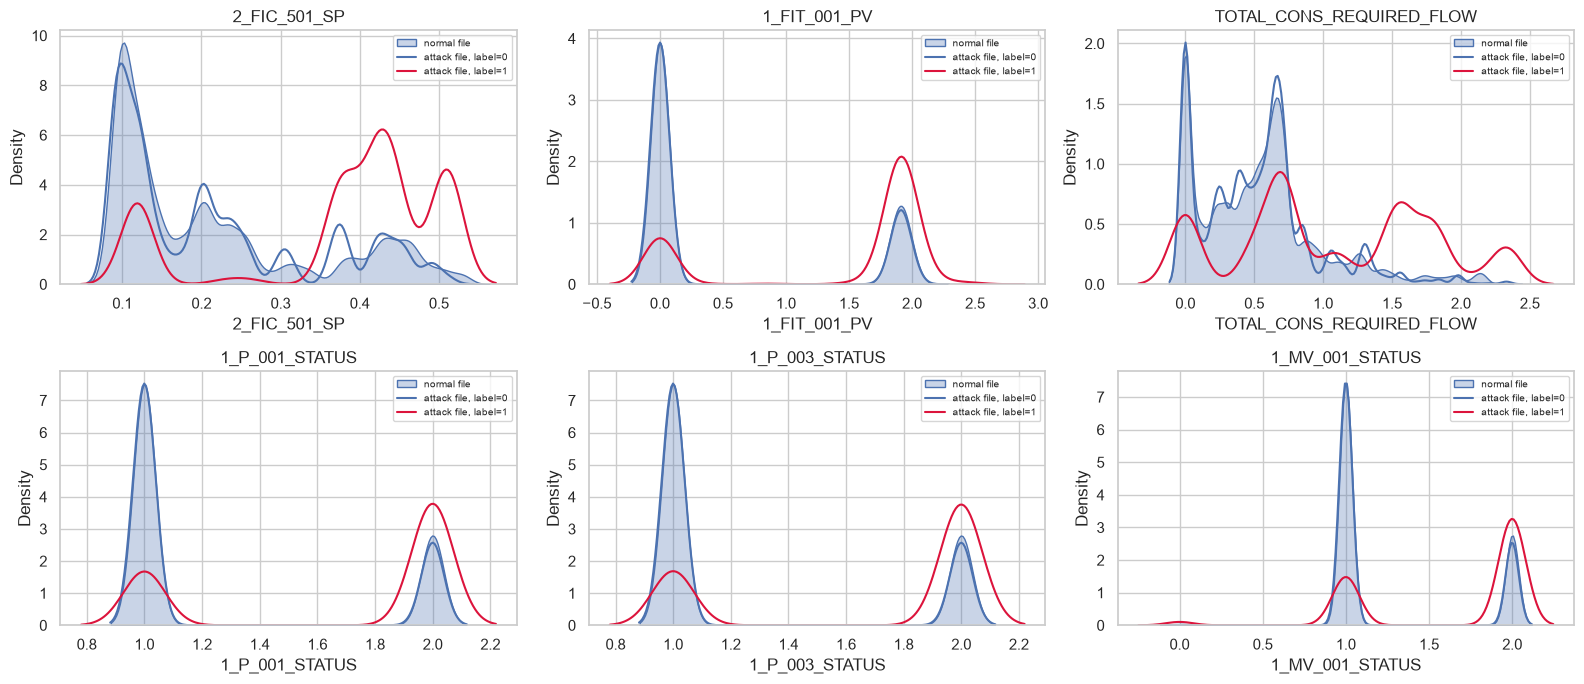

In [ ]:
a_norm = attack_df[attack_df.ATTACK == 0]
a_att = attack_df[attack_df.ATTACK == 1]
n_sample = normal_df[FEATURES].sample(min(200_000, len(normal_df)), random_state=0)

ks = pd.DataFrame({
    "KS_attack": {c: stats.ks_2samp(n_sample[c], a_att[c]).statistic for c in FEATURES},
    "KS_drift":  {c: stats.ks_2samp(n_sample[c], a_norm[c]).statistic for c in FEATURES},
})
ks["attack_minus_drift"] = ks.KS_attack - ks.KS_drift
display(ks.sort_values("KS_drift", ascending=False).head(10).round(3).style.set_caption("Largest normal->attack-file DRIFT (false-positive risk)"))
display(ks.sort_values("attack_minus_drift", ascending=False).head(10).round(3).style.set_caption("Sensors where ATTACK rows differ beyond drift"))

top = ks.sort_values("attack_minus_drift", ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.flat, top):
    sns.kdeplot(n_sample[c], ax=ax, label="normal file", fill=True, alpha=.3, warn_singular=False)
    sns.kdeplot(a_norm[c], ax=ax, label="attack file, label=0", warn_singular=False)
    sns.kdeplot(a_att[c], ax=ax, label="attack file, label=1", color="crimson", warn_singular=False)
    ax.set_title(c); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Time series with attack windows shaded (fixed)

,start,end,duration_s
A1,2017-10-09 19:25:03,2017-10-09 19:50:03,1501.0
A2,2017-10-10 10:24:13,2017-10-10 10:34:03,591.0
A3,2017-10-10 10:55:03,2017-10-10 11:24:03,1741.0
A4,2017-10-10 11:30:43,2017-10-10 11:44:53,851.0
A5,2017-10-10 13:39:33,2017-10-10 13:50:43,671.0
A6,2017-10-10 14:48:20,2017-10-10 14:59:58,699.0
A7,2017-10-10 17:40:03,2017-10-10 17:49:43,581.0
A8,2017-10-11 00:07:33,2017-10-11 00:10:55,203.0
A9,2017-10-11 10:55:03,2017-10-11 10:56:30,88.0
A10,2017-10-11 11:17:57,2017-10-11 11:31:23,807.0


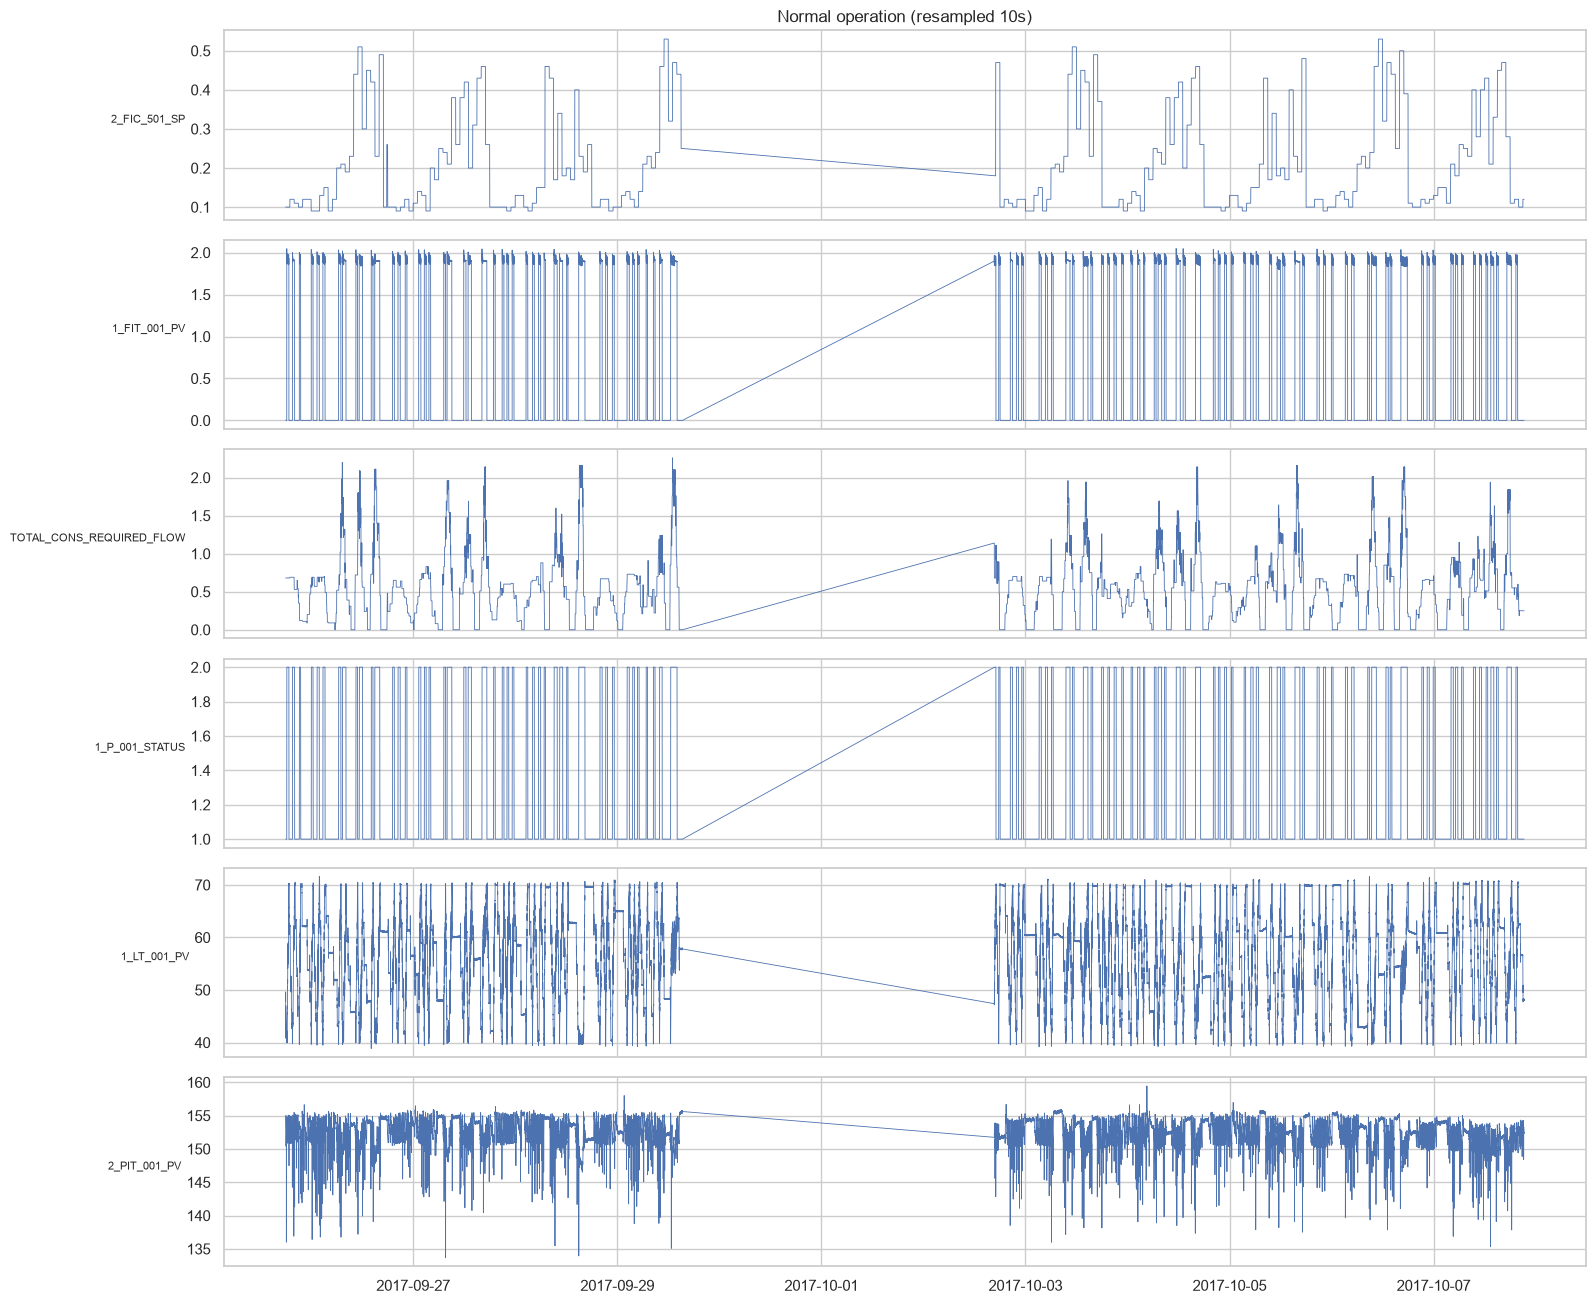

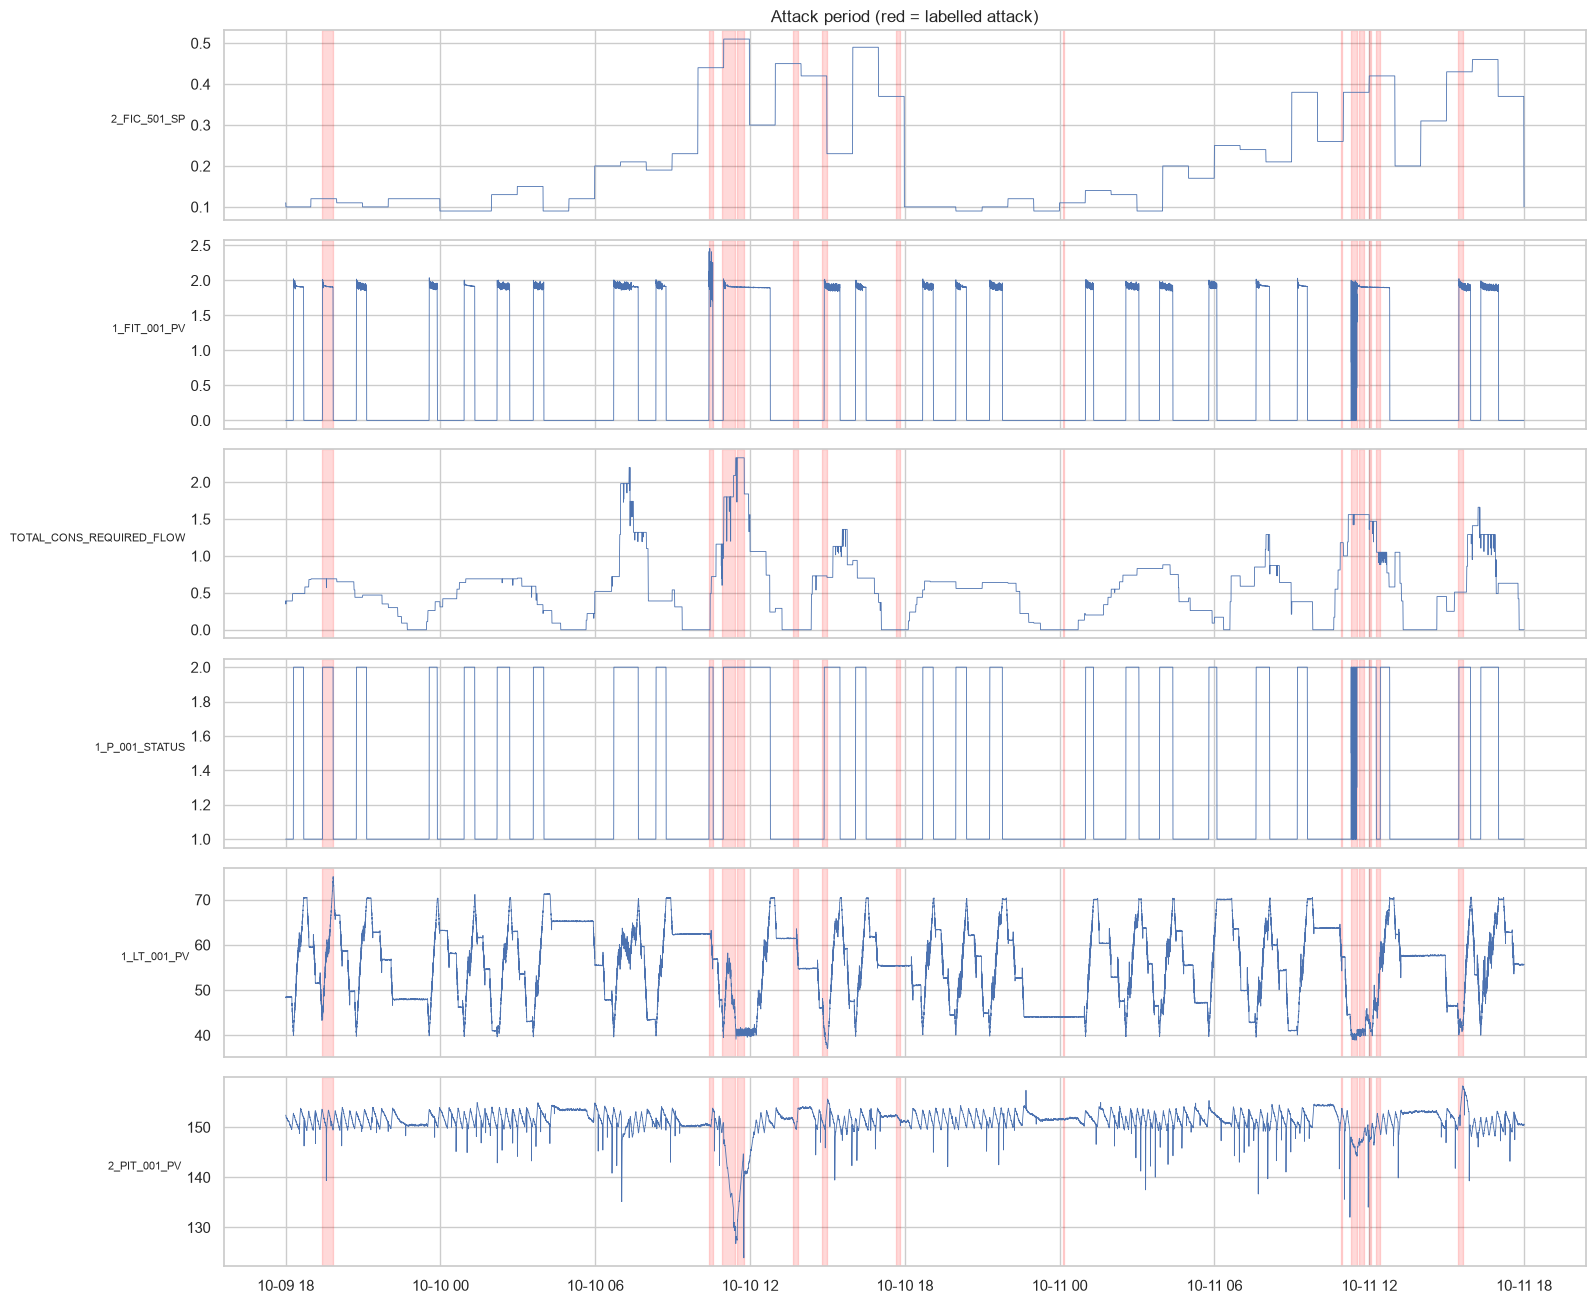

In [ ]:
def attack_segments(label):
    """Contiguous runs of label==1 -> DataFrame(start, end, duration_s)."""
    lab = label.astype(int).to_numpy()
    edges = np.diff(np.r_[0, lab, 0])
    s, e = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1) - 1
    idx = label.index
    seg = pd.DataFrame({"start": idx[s], "end": idx[e]})
    seg["duration_s"] = (seg.end - seg.start).dt.total_seconds() + 1
    seg.index = [f"A{i+1}" for i in range(len(seg))]
    return seg

SEG = attack_segments(attack_df["ATTACK"])
display(SEG)

def plot_with_attacks(df, sensors, title, seg=None):
    fig, axes = plt.subplots(len(sensors), 1, figsize=(16, 2.2 * len(sensors)), sharex=True)
    for ax, s in zip(np.atleast_1d(axes), sensors):
        ax.plot(df.index, df[s], lw=.6)
        ax.set_ylabel(s, rotation=0, ha="right", fontsize=8)
        if seg is not None:
            for name, r in seg.iterrows():
                ax.axvspan(r.start, r.end, color="red", alpha=.15)
    np.atleast_1d(axes)[0].set_title(title)
    plt.tight_layout(); plt.show()

SENSORS_TO_PLOT = list(top[:4]) + ["1_LT_001_PV", "2_PIT_001_PV"]
SENSORS_TO_PLOT = [s for s in dict.fromkeys(SENSORS_TO_PLOT) if s in FEATURES]
plot_with_attacks(n_rs, SENSORS_TO_PLOT, f"Normal operation (resampled {RESAMPLE})")
plot_with_attacks(a_rs, SENSORS_TO_PLOT, f"Attack period (red = labelled attack)", SEG)

---
# New: relationships between sensors and patterns
## A. Clustered correlation map (all informative sensors)
v1 showed the *first 30 columns*, which included constant ones (blank rows). This version uses every informative sensor with **Spearman** correlation, which is robust to on/off non-linearity, and orders it by hierarchical clustering so co-moving groups form blocks. The groups correspond to physical subsystems and are good candidates for **per-subsystem models**, or for checking that the LSTM-AE reconstructs a whole group consistently.

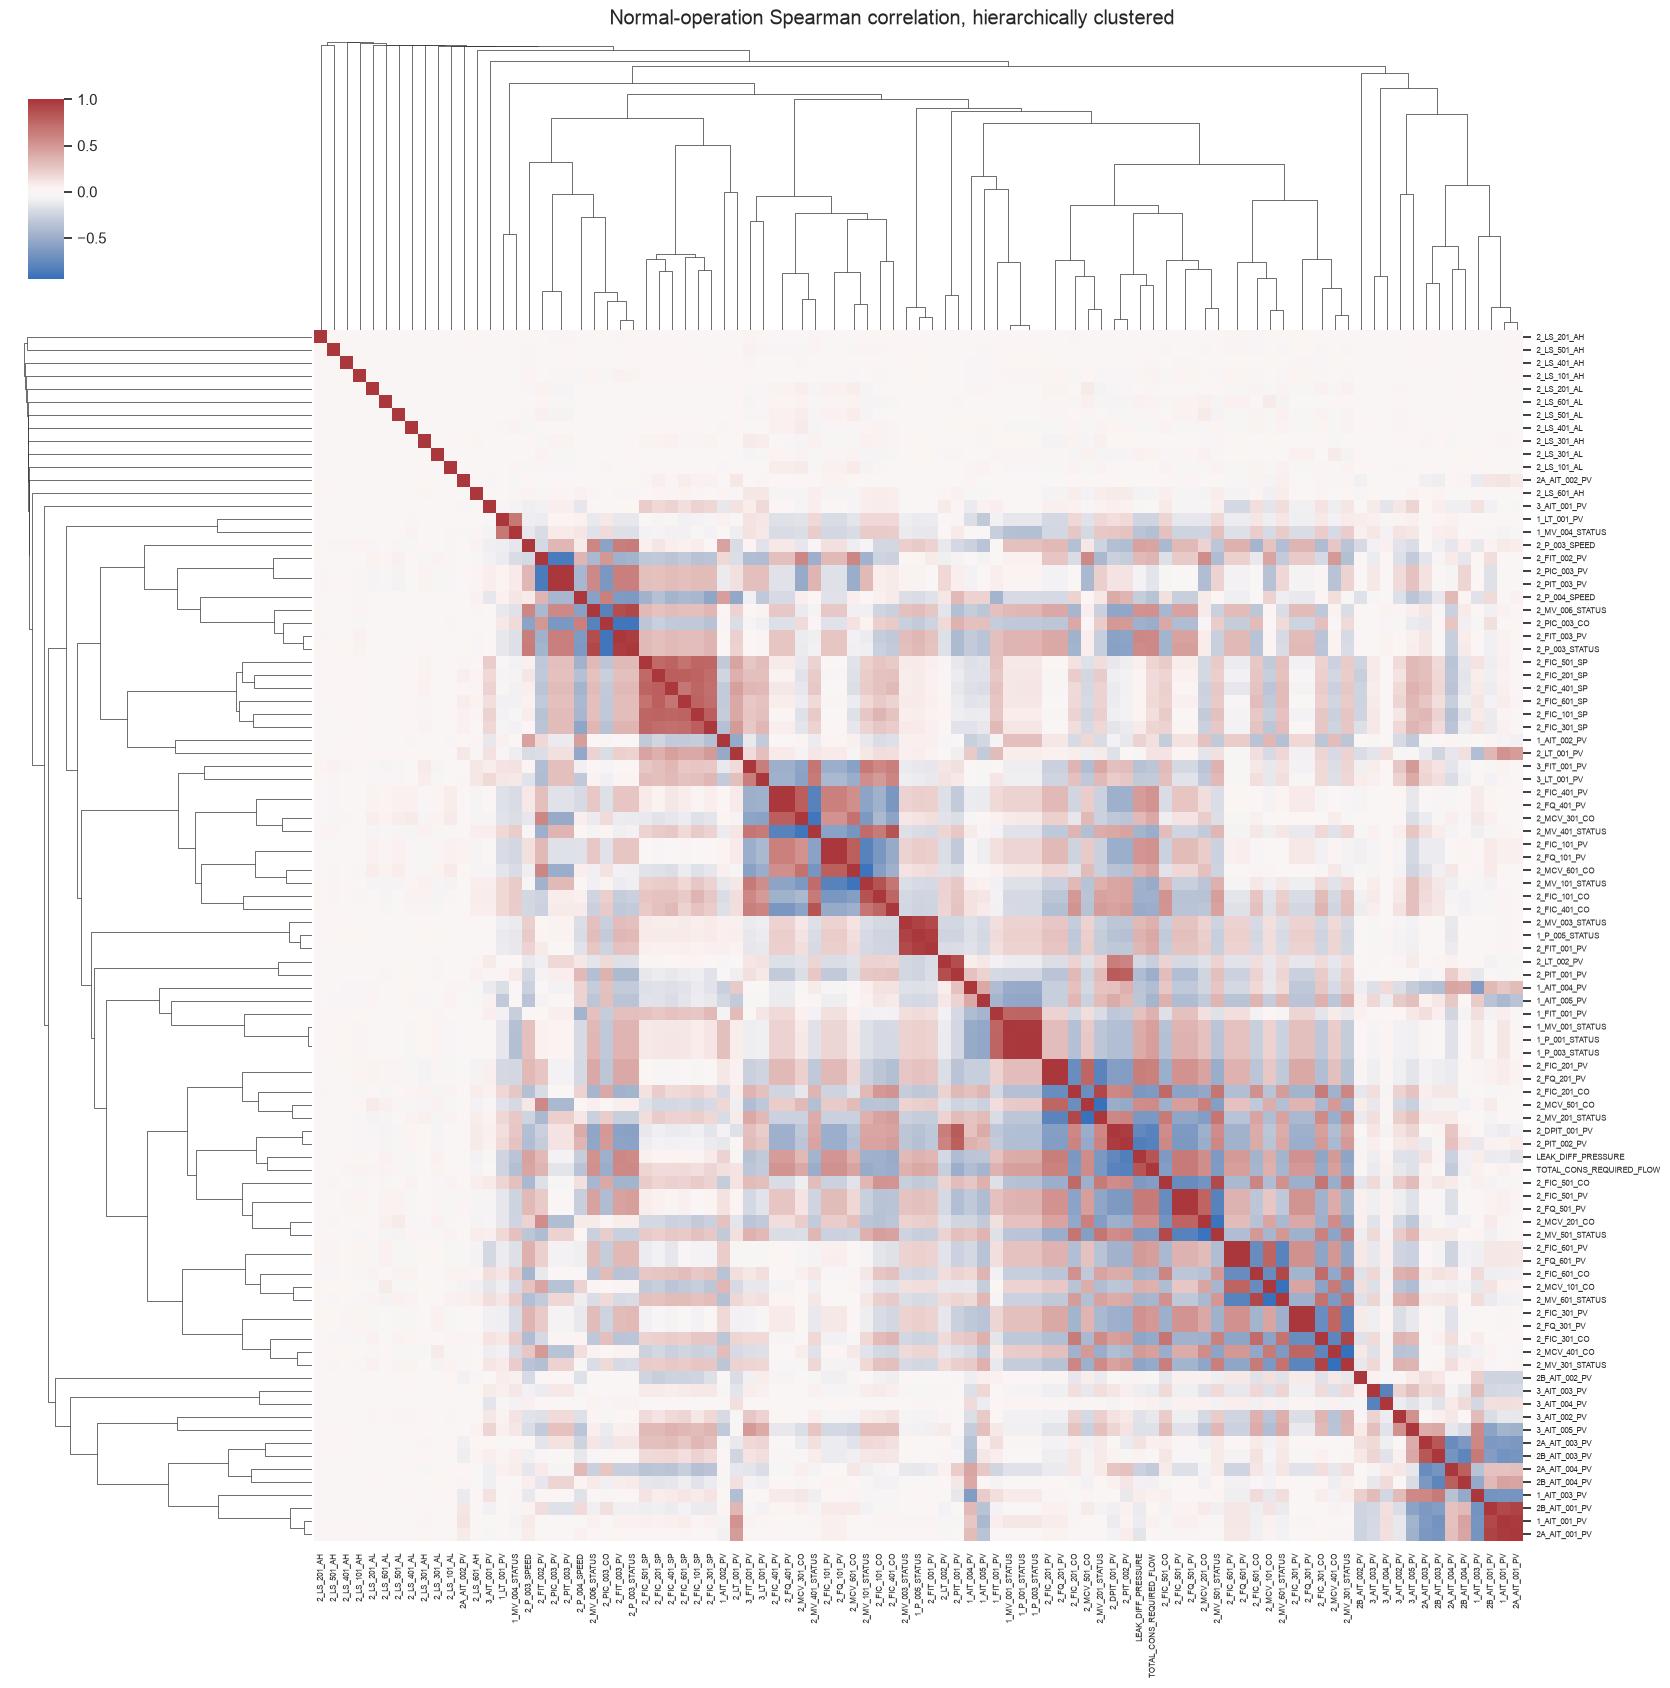

17 sensor groups with |rho| >= 0.7:
  G9 (6): ['2_FIC_101_SP', '2_FIC_201_SP', '2_FIC_301_SP', '2_FIC_401_SP', '2_FIC_501_SP', '2_FIC_601_SP']
  G22 (5): ['2_FIC_201_CO', '2_FIC_201_PV', '2_FQ_201_PV', '2_MCV_501_CO', '2_MV_201_STATUS']
  G24 (5): ['2_FIC_501_CO', '2_FIC_501_PV', '2_FQ_501_PV', '2_MCV_201_CO', '2_MV_501_STATUS']
  G25 (5): ['2_FIC_601_CO', '2_FIC_601_PV', '2_FQ_601_PV', '2_MCV_101_CO', '2_MV_601_STATUS']
  G26 (5): ['2_FIC_301_CO', '2_FIC_301_PV', '2_FQ_301_PV', '2_MCV_401_CO', '2_MV_301_STATUS']
  G6 (4): ['2_FIT_003_PV', '2_MV_006_STATUS', '2_P_003_STATUS', '2_PIC_003_CO']
  G14 (4): ['2_FIC_401_PV', '2_FQ_401_PV', '2_MCV_301_CO', '2_MV_401_STATUS']
  G15 (4): ['2_FIC_101_PV', '2_FQ_101_PV', '2_MCV_601_CO', '2_MV_101_STATUS']
  G19 (4): ['1_FIT_001_PV', '1_MV_001_STATUS', '1_P_001_STATUS', '1_P_003_STATUS']
  G23 (4): ['2_DPIT_001_PV', '2_PIT_002_PV', 'LEAK_DIFF_PRESSURE', 'TOTAL_CONS_REQUIRED_FLOW']
  G30 (4): ['2A_AIT_003_PV', '2A_AIT_004_PV', '2B_AIT_003_PV', '2B_

In [ ]:
corr = n_rs[FEATURES].corr(method="spearman").fillna(0)
dist = (1 - corr.abs()).to_numpy(copy=True)
np.fill_diagonal(dist, 0)
dist = (dist + dist.T) / 2
Z = hierarchy.linkage(squareform(dist, checks=False), method="average")

g = sns.clustermap(corr, row_linkage=Z, col_linkage=Z, cmap="vlag", center=0,
                   figsize=(18, 18), xticklabels=True, yticklabels=True, cbar_pos=(0.02, .85, .02, .1))
g.ax_heatmap.tick_params(labelsize=6)
g.fig.suptitle("Normal-operation Spearman correlation, hierarchically clustered", y=1.0)
plt.show()

CLUSTER_CUT = 0.3          # |rho| >= 0.7 inside a cluster
clusters = pd.Series(hierarchy.fcluster(Z, t=CLUSTER_CUT, criterion="distance"), index=FEATURES)
groups = {k: v.index.tolist() for k, v in clusters.groupby(clusters) if len(v) > 1}
print(f"{len(groups)} sensor groups with |rho| >= {1 - CLUSTER_CUT}:")
for k, members in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"  G{k} ({len(members)}): {members}")

In [ ]:
# Strongest pairs, and near-duplicates (|rho| > 0.98 -> redundant for Isolation Forest)
iu = np.triu_indices_from(corr, k=1)
pairs = pd.DataFrame({"a": corr.index[iu[0]], "b": corr.columns[iu[1]], "rho": corr.values[iu]})
pairs["abs"] = pairs.rho.abs()
pairs = pairs.sort_values("abs", ascending=False)
pairs["cross_stage"] = pairs.a.map(tax.stage) != pairs.b.map(tax.stage)
display(pairs.head(25).round(3))
print("Near-duplicate pairs (|rho|>0.98):", (pairs["abs"] > .98).sum())
print("Strong CROSS-STAGE links (|rho|>0.8) - these show how stages are physically coupled:")
display(pairs[(pairs["abs"] > .8) & pairs.cross_stage].head(15).round(3))

,a,b,rho,abs,cross_stage
792,1_P_001_STATUS,1_P_003_STATUS,1.000,1.000,False
2078,2_FIC_501_PV,2_FQ_501_PV,1.000,1.000,False
2271,2_FIC_601_PV,2_FQ_601_PV,1.000,1.000,False
1876,2_FIC_401_PV,2_FQ_401_PV,1.000,1.000,False
1216,2_FIC_101_PV,2_FQ_101_PV,1.000,1.000,False
1445,2_FIC_201_PV,2_FQ_201_PV,1.000,1.000,False
1665,2_FIC_301_PV,2_FQ_301_PV,1.000,1.000,False
4070,2_PIC_003_PV,2_PIT_003_PV,1.000,1.000,False
624,1_MV_001_STATUS,1_P_001_STATUS,0.985,0.985,False
625,1_MV_001_STATUS,1_P_003_STATUS,0.985,0.985,False


Near-duplicate pairs (|rho|>0.98): 10
Strong CROSS-STAGE links (|rho|>0.8) - these show how stages are physically coupled:


,a,b,rho,abs,cross_stage
75,1_AIT_001_PV,2A_AIT_001_PV,0.972,0.972,True
976,1_P_005_STATUS,2_FIT_001_PV,0.957,0.957,True
1005,1_P_005_STATUS,2_MV_003_STATUS,0.943,0.943,True
4145,2A_AIT_001_PV,2B_AIT_001_PV,0.936,0.936,True
79,1_AIT_001_PV,2B_AIT_001_PV,0.908,0.908,True
4176,2A_AIT_003_PV,2B_AIT_003_PV,0.839,0.839,True
4123,2_PIT_002_PV,LEAK_DIFF_PRESSURE,-0.838,0.838,True
4124,2_PIT_002_PV,TOTAL_CONS_REQUIRED_FLOW,-0.820,0.820,True
1117,2_DPIT_001_PV,TOTAL_CONS_REQUIRED_FLOW,-0.810,0.810,True


## B. Control-loop health: PV vs SP vs CO
Each `2_FIC_x01` loop has a setpoint (SP), measured value (PV) and controller output (CO). In normal operation PV tracks SP, and CO is consistent with the SP. Many WaDi attacks either **change the SP** or **spoof the PV**, so the *tracking error* `PV − SP` and the `CO`-to-`PV` relationship are physics-based features. They often separate attacks better than the raw tags, and an LLM can explain them easily ("flow did not follow its setpoint for 4 min").

MAE(PV-SP)                  p99|PV-SP|                  corr(CO,PV)  \
set         attack:0 attack:1  normal   attack:0 attack:1  normal    attack:0   
loop                                                                            
2_FIC_101     0.1471   0.0925  0.1286     0.4627   0.4197  0.4828     -0.4339   
2_FIC_201     0.1089   0.1085  0.1149     0.3857   0.3720  0.4659     -0.4518   
2_FIC_301     0.1407   0.1661  0.1240     0.4328   0.3628  0.4828     -0.5212   
2_FIC_401     0.1204   0.1171  0.1148     0.4628   0.4728  0.4928     -0.4064   
2_FIC_501     0.1239   0.2168  0.1198     0.4328   0.4925  0.4893     -0.3796   
2_FIC_601     0.1326   0.1774  0.1260     0.4728   0.4314  0.4724     -0.4788   
2_PIC_003     0.8532   0.6458  0.8272     0.9817   0.9939  0.9856     -0.9081   

                           corr(SP,PV)                   
set       attack:1  normal    attack:0 attack:1  normal  
loop                                                     
2_FIC_101  -0.4222 -0.3897      0.1262   0.3879  0.2004  
2_FIC_201  -0.4399 -0.5196      0.3095   0.2706  0.1713  
2_FIC_301  -0.6750 -0.5285      0.0306   0.1596  0.2102  
2_FIC_401  -0.4995 -0.4323      0.1748   0.4460  0.2101  
2_FIC_501  -0.7756 -0.5041      0.2682   0.2418  0.2742  
2_FIC_601  -0.5934 -0.5135      0.0602  -0.3348  0.2137  
2_PIC_003  -0.8923 -0.9303     -0.0273      NaN     NaN

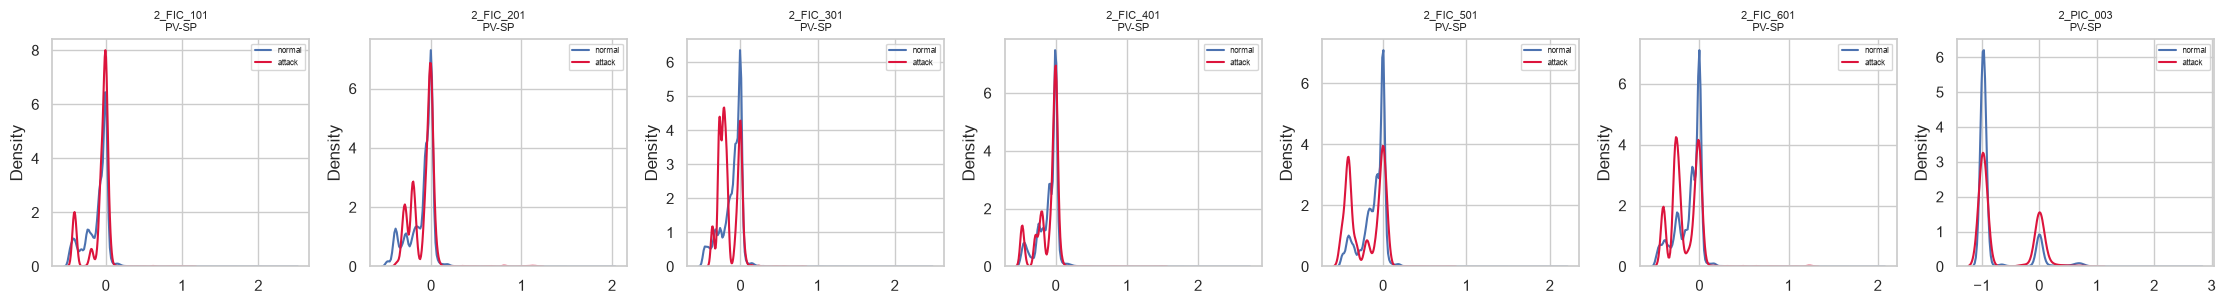

In [ ]:
loops = sorted({m.group(1) for c in FEATURES + const_normal if (m := re.match(r"^(.*_(?:FIC|PIC)_\d+)_(PV|SP|CO)$", c))})
rows = []
for L in loops:
    pv, sp, co = f"{L}_PV", f"{L}_SP", f"{L}_CO"
    if not all(x in normal_df.columns for x in (pv, sp, co)):
        continue
    for name, d in [("normal", normal_df), ("attack:0", a_norm), ("attack:1", a_att)]:
        err = d[pv] - d[sp]
        rows.append({"loop": L, "set": name, "MAE(PV-SP)": err.abs().mean(),
                     "p99|PV-SP|": err.abs().quantile(.99),
                     "corr(CO,PV)": d[co].corr(d[pv]), "corr(SP,PV)": d[sp].corr(d[pv])})
loop_df = pd.DataFrame(rows).set_index(["loop", "set"]).round(4)
display(loop_df.unstack("set"))

fig, axes = plt.subplots(1, len(loops), figsize=(3.2 * len(loops), 3.2), sharey=False)
for ax, L in zip(np.atleast_1d(axes), loops):
    if f"{L}_PV" not in normal_df.columns: continue
    nn = normal_df.iloc[::20]
    sns.kdeplot(nn[f"{L}_PV"] - nn[f"{L}_SP"], ax=ax, label="normal", warn_singular=False)
    sns.kdeplot(a_att[f"{L}_PV"] - a_att[f"{L}_SP"], ax=ax, label="attack", color="crimson", warn_singular=False)
    ax.set_title(f"{L}\nPV-SP", fontsize=8); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## C. Actuator → sensor effects (what each pump/valve actually drives)
For each discrete actuator, the cell compares each continuous sensor's mean between the actuator's states, using a standardised effect size (Cohen's *d*). Large |d| means "when this valve/pump changes state, that sensor moves". This gives a data-driven picture of the plant's wiring, an **invariant list** (e.g. `pump ON ⇒ flow > x`) you can check in the attack data, and context for the LLM explanations.

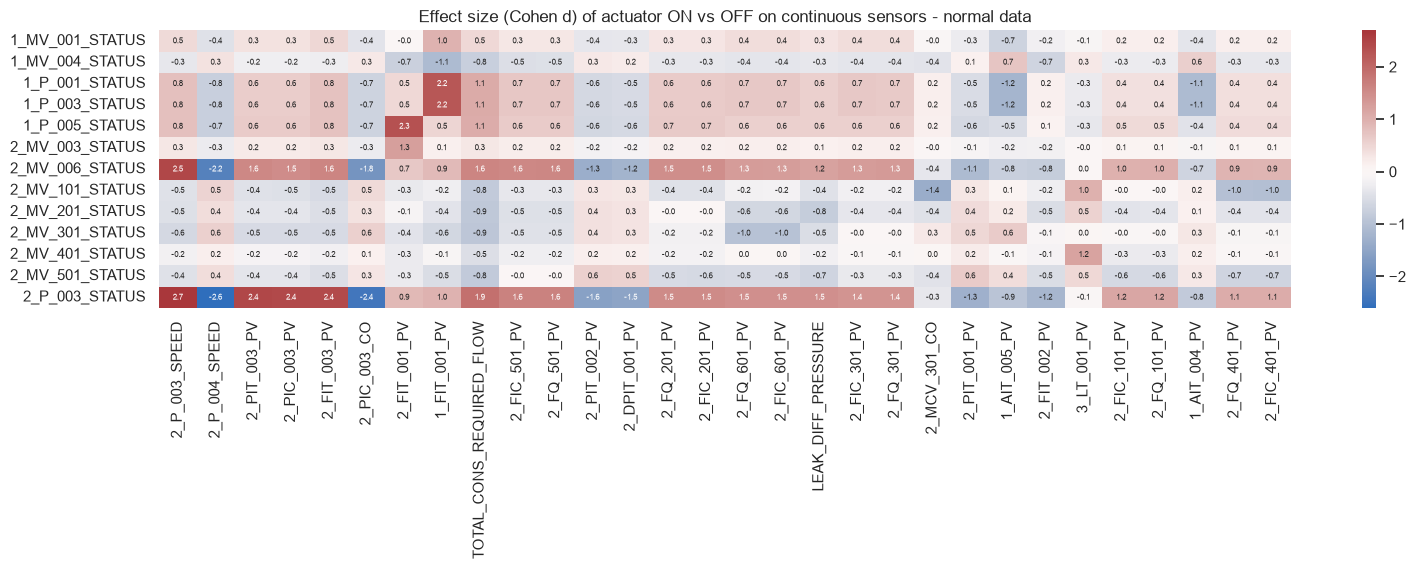

,actuator,sensor,d
847,2_P_003_STATUS,2_P_003_SPEED,2.69
848,2_P_003_STATUS,2_P_004_SPEED,-2.61
445,2_MV_006_STATUS,2_P_003_SPEED,2.46
853,2_P_003_STATUS,2_PIT_003_PV,2.45
850,2_P_003_STATUS,2_PIC_003_PV,2.44
832,2_P_003_STATUS,2_FIT_003_PV,2.42
849,2_P_003_STATUS,2_PIC_003_CO,-2.42
294,1_P_005_STATUS,2_FIT_001_PV,2.34
206,1_P_003_STATUS,1_FIT_001_PV,2.25
139,1_P_001_STATUS,1_FIT_001_PV,2.25


In [ ]:
act = [c for c in DISC if tax.loc[c, "type"] in ("P", "MV", "SV") and n_rs[c].nunique() > 1]
eff = pd.DataFrame(index=act, columns=CONT, dtype=float)
nd = normal_df[act + CONT].iloc[::5]                          # 0.2 Hz subsample is plenty
for a in act:
    on = nd[a] == nd[a].max(); off = nd[a] == nd[a].min()
    if on.sum() < 100 or off.sum() < 100: continue
    m1, m0 = nd.loc[on, CONT].mean(), nd.loc[off, CONT].mean()
    sd = nd[CONT].std().replace(0, np.nan)
    eff.loc[a] = (m1 - m0) / sd
eff = eff.dropna(how="all").dropna(how="all", axis=1)

keep = eff.abs().max().sort_values(ascending=False).index[:30]
plt.figure(figsize=(16, max(3, .45 * len(eff))))
sns.heatmap(eff[keep].astype(float), cmap="vlag", center=0, annot=len(eff) < 15, fmt=".1f", annot_kws={"size": 6})
plt.title("Effect size (Cohen d) of actuator ON vs OFF on continuous sensors - normal data")
plt.tight_layout(); plt.show()

links = eff.stack().rename("d").reset_index().rename(columns={"level_0": "actuator", "level_1": "sensor"})
links = links.reindex(links.d.abs().sort_values(ascending=False).index)
display(links.head(20).round(2))

In [ ]:
# Turn the strongest links into simple invariants and test them on the attack file.
# Rule: when actuator is ON, sensor stays within the normal [p0.5, p99.5] band seen while ON (same for OFF).
def invariant_violations(link_rows, n=10):
    out = []
    for _, r in link_rows.drop_duplicates("actuator").head(n).iterrows():
        a, s = r.actuator, r.sensor
        for state in (normal_df[a].min(), normal_df[a].max()):
            ref = normal_df.loc[normal_df[a] == state, s]
            lo, hi = ref.quantile([.005, .995])
            pad = 0.1 * normal_df[s].std(); lo, hi = lo - pad, hi + pad
            sub = attack_df[attack_df[a] == state]
            if len(sub) == 0: continue
            viol = (sub[s] < lo) | (sub[s] > hi)
            out.append({"rule": f"{a}=={state:g} -> {s} in [{lo:.3g},{hi:.3g}]",
                        "viol_rate_label0": viol[sub.ATTACK == 0].mean(),
                        "viol_rate_label1": viol[sub.ATTACK == 1].mean()})
    return pd.DataFrame(out).sort_values("viol_rate_label1", ascending=False)

display(invariant_violations(links).round(4))

,rule,viol_rate_label0,viol_rate_label1
17,"1_MV_004_STATUS==2 -> 1_FIT_001_PV in [-0.084,...",0.0033,0.4595
16,"1_MV_004_STATUS==0 -> 1_FIT_001_PV in [-0.084,...",0.0000,0.2609
8,"1_P_001_STATUS==1 -> 1_FIT_001_PV in [-0.084,0...",0.0003,0.2020
6,"1_P_003_STATUS==1 -> 1_FIT_001_PV in [-0.084,0...",0.0004,0.1983
9,"1_P_001_STATUS==2 -> 1_FIT_001_PV in [1.73,2.1]",0.0022,0.0626
7,"1_P_003_STATUS==2 -> 1_FIT_001_PV in [1.73,2.1]",0.0020,0.0582
4,"1_P_005_STATUS==1 -> 2_FIT_001_PV in [-0.0939,...",0.0047,0.0317
5,"1_P_005_STATUS==2 -> 2_FIT_001_PV in [-0.0939,...",0.0001,0.0146
13,2_MV_003_STATUS==2 -> 2_FIT_001_PV in [-0.0939...,0.0001,0.0146
12,2_MV_003_STATUS==0 -> 2_FIT_001_PV in [-0.0939...,0.0000,0.0138


## D. Lead/lag relationships (cross-correlation)
Water takes time to travel, so many relationships are **delayed**. Example: inflow → tank level rises later, and outflow → downstream pressure later. For the strongest pairs, the cell finds the lag that maximises correlation of the *differenced* signals. Differencing removes shared trends that would inflate correlation.
* Lag > 0 means **a leads b**. This suggests causal direction and a minimum LSTM window length.
* A clear tank mass balance: `d(level)/dt ≈ k·(inflow − outflow)`. The residual of this balance is a strong physics feature.

In [ ]:
MAX_LAG_STEPS = 60          # 60 x 10 s = 10 min
step_s = pd.Timedelta(RESAMPLE).total_seconds()

def best_lag(x, y, max_lag=MAX_LAG_STEPS):
    x = (x - x.mean()) / (x.std() + 1e-9); y = (y - y.mean()) / (y.std() + 1e-9)
    lags = range(-max_lag, max_lag + 1)
    cc = [x.corr(y.shift(-l)) for l in lags]          # positive l: x leads y
    i = int(np.nanargmax(np.abs(cc)))
    return list(lags)[i], cc[i], cc[max_lag]

dn = n_rs[CONT_DYN].diff().dropna()
cand = pairs[pairs.a.isin(CONT_DYN) & pairs.b.isin(CONT_DYN) & (pairs["abs"] > .5)].head(80)
lag_rows = []
for _, r in cand.iterrows():
    l, c_best, c0 = best_lag(dn[r.a], dn[r.b])
    lag_rows.append({"a": r.a, "b": r.b, "rho_level": r.rho, "best_lag_s": l * step_s,
                     "xcorr@lag": c_best, "xcorr@0": c0})
lag_df = pd.DataFrame(lag_rows)
lag_df = lag_df[(lag_df.best_lag_s != 0) & (lag_df.best_lag_s.abs() < MAX_LAG_STEPS * step_s)]   # boundary hits = no real peak
lag_df = lag_df.reindex(lag_df["xcorr@lag"].abs().sort_values(ascending=False).index)
display(lag_df.dropna().head(20).round(3))
print("Largest useful lag (s):", lag_df.loc[lag_df["xcorr@lag"].abs() > .3, "best_lag_s"].abs().max(),
      "-> LSTM-AE window should be at least this long")

,a,b,rho_level,best_lag_s,xcorr@lag,xcorr@0
17,2_PIT_002_PV,LEAK_DIFF_PRESSURE,-0.838,20.0,-0.610,0.166
32,2_DPIT_001_PV,LEAK_DIFF_PRESSURE,-0.768,20.0,-0.602,0.173
64,2_FQ_501_PV,LEAK_DIFF_PRESSURE,0.657,20.0,0.470,-0.082
62,2_FIC_501_PV,LEAK_DIFF_PRESSURE,0.657,20.0,0.457,-0.077
70,2_FIC_101_CO,2_FQ_101_PV,-0.652,-10.0,-0.446,-0.363
69,2_FIC_101_CO,2_FIC_101_PV,-0.652,-10.0,-0.442,-0.380
43,2_FIC_601_CO,2_FQ_601_PV,-0.732,-10.0,-0.425,-0.388
42,2_FIC_601_CO,2_FIC_601_PV,-0.732,-10.0,-0.422,-0.402
45,2_FIC_501_CO,2_FQ_501_PV,-0.730,-10.0,-0.413,-0.364
51,2_FIC_301_CO,2_FQ_301_PV,-0.723,-10.0,-0.412,-0.369


Largest useful lag (s): 20.0 -> LSTM-AE window should be at least this long


dL/dt = 0.1394*qin + -0.1391*qout + -0.0015   R2=0.047


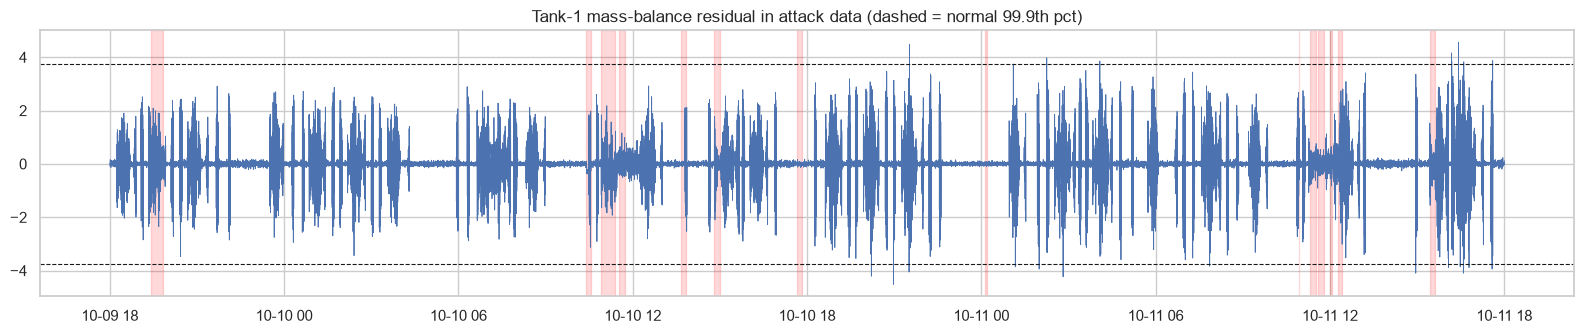

In [ ]:
# Mass balance of the stage-1 tank: d(LT_001)/dt vs (inflow 1_FIT_001 - outflow 2_FIT_001)
LVL, QIN, QOUT = "1_LT_001_PV", "1_FIT_001_PV", "2_FIT_001_PV"
if all(c in FEATURES for c in (LVL, QIN, QOUT)):
    from sklearn.linear_model import LinearRegression
    def balance_frame(d):
        f = pd.DataFrame({"dL": d[LVL].diff(), "qin": d[QIN], "qout": d[QOUT]}).dropna()
        return f
    fn = balance_frame(n_rs)
    lr = LinearRegression().fit(fn[["qin", "qout"]], fn.dL)
    print(f"dL/dt = {lr.coef_[0]:.4f}*qin + {lr.coef_[1]:.4f}*qout + {lr.intercept_:.4f}   R2={lr.score(fn[['qin','qout']], fn.dL):.3f}")
    fa = balance_frame(a_rs)
    fa["resid"] = fa.dL - lr.predict(fa[["qin", "qout"]])
    thr = (fn.dL - lr.predict(fn[["qin", "qout"]])).abs().quantile(.999)
    fig, ax = plt.subplots(figsize=(16, 3.5))
    ax.plot(fa.index, fa.resid, lw=.6)
    ax.axhline(thr, color="k", ls="--", lw=.8); ax.axhline(-thr, color="k", ls="--", lw=.8)
    for _, r in SEG.iterrows(): ax.axvspan(r.start, r.end, color="red", alpha=.15)
    ax.set_title("Tank-1 mass-balance residual in attack data (dashed = normal 99.9th pct)")
    plt.tight_layout(); plt.show()
else:
    print("Tank columns not all informative; skipped.")

## E. Daily cycles and temporal memory
Water demand follows a daily pattern. If a sensor has a strong hour-of-day profile, the model needs either time-of-day features or a training set covering every hour. Otherwise a normal evening peak will look anomalous. Autocorrelation decay shows how far back the signal "remembers", which is a guide for the LSTM sequence length.

Share of a sensor's variance explained by hour-of-day (top 10):


,hod_std / total_std
2_LT_001_PV,0.746
1_AIT_002_PV,0.582
2_FIC_601_CO,0.562
2_P_004_SPEED,0.552
3_AIT_005_PV,0.544
3_FIT_001_PV,0.521
2_FIC_101_CO,0.507
2B_AIT_002_PV,0.497
3_LT_001_PV,0.479
2_FIT_002_PV,0.466


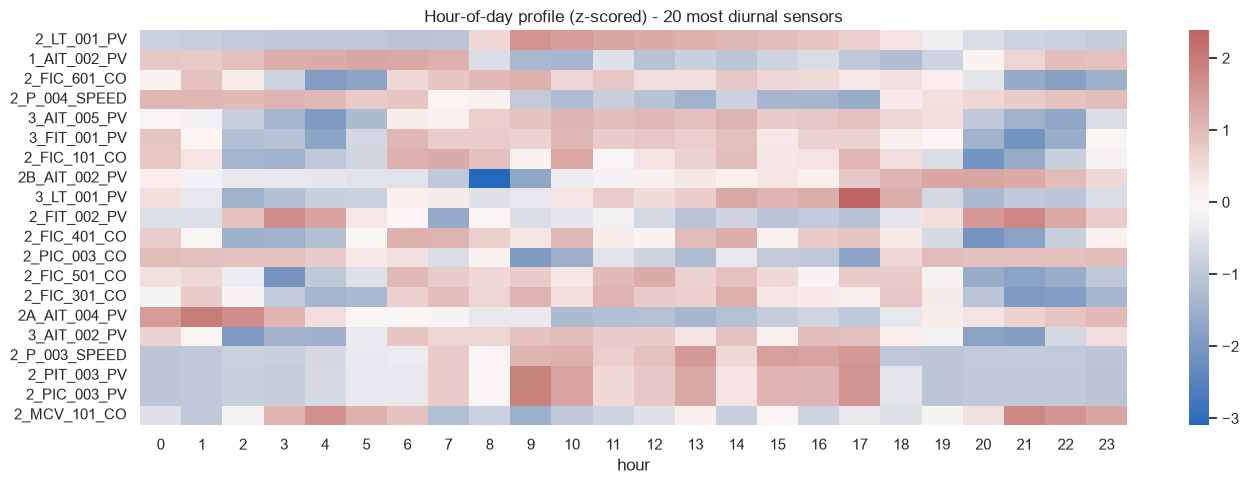

ACF 1/e decay time - median 26.7 min, 25-75% [20.3, 45.0] min


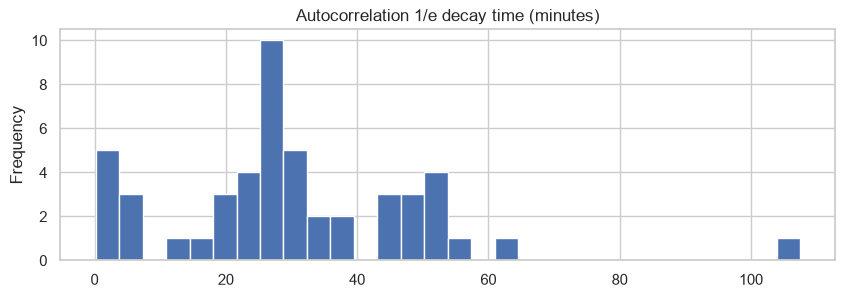

In [ ]:
hod = n_rs[CONT_DYN].groupby(n_rs.index.hour).mean()
hod_strength = (hod.std() / n_rs[CONT_DYN].std()).sort_values(ascending=False)
print("Share of a sensor's variance explained by hour-of-day (top 10):")
display(hod_strength.head(10).round(3).to_frame("hod_std / total_std"))

z = (hod - hod.mean()) / hod.std()
plt.figure(figsize=(14, 5))
sns.heatmap(z[hod_strength.index[:20]].T, cmap="vlag", center=0)
plt.title("Hour-of-day profile (z-scored) - 20 most diurnal sensors"); plt.xlabel("hour")
plt.tight_layout(); plt.show()

# autocorrelation decay: lag where ACF first drops below 1/e
def acf_decay(x, max_lag=720):
    x = x.dropna().to_numpy(); x = x - x.mean(); v = (x * x).sum()
    if v == 0: return np.nan
    for l in range(1, max_lag):
        if (x[:-l] * x[l:]).sum() / v < 1 / np.e:
            return l * step_s
    return np.nan
decay = pd.Series({c: acf_decay(n_rs[c]) for c in CONT_DYN}).dropna().sort_values()
print(f"ACF 1/e decay time - median {decay.median()/60:.1f} min, 25-75% "
      f"[{decay.quantile(.25)/60:.1f}, {decay.quantile(.75)/60:.1f}] min")
decay.div(60).plot.hist(bins=30, title="Autocorrelation 1/e decay time (minutes)", figsize=(10, 3)); plt.show()

## F. Operating modes: actuator state combinations
Treat the vector of all actuator states as the plant's "mode". Normal operation usually uses only a few modes. Rows in the attack file with **combinations never seen in normal** are a cheap, interpretable detector and very easy for an operator to understand.

In [ ]:
act_all = [c for c in DISC if c in attack_df.columns]
mode_n = normal_df[act_all].round().astype(int).astype(str).agg("".join, axis=1)
mode_a = attack_df[act_all].round().astype(int).astype(str).agg("".join, axis=1)
freq = mode_n.value_counts(normalize=True)
print(f"Distinct actuator modes in normal: {len(freq)}; top 5 cover {freq.head(5).sum():.1%}")
display(freq.head(10).to_frame("share"))

unseen = ~mode_a.isin(freq.index)
ct = pd.crosstab(unseen.rename("unseen_mode"), attack_df.ATTACK.rename("ATTACK"), normalize="columns")
display(ct.round(4))
print("Precision of 'unseen mode' as alarm:",
      round(attack_df.ATTACK[unseen].mean(), 3) if unseen.any() else "n/a",
      "| recall:", round(unseen[attack_df.ATTACK == 1].mean(), 3))

# which actuators differ from the closest normal mode during each attack
def changed_actuators(start, end):
    seg = attack_df.loc[start:end, act_all].round()
    usual = normal_df[act_all].round().mode().iloc[0]
    before = attack_df.loc[start - pd.Timedelta("10min"):start, act_all].round().mode().iloc[0]
    diff = (seg.mode().iloc[0] != before)
    return diff[diff].index.tolist()
SEG["actuators_changed_vs_10min_before"] = [changed_actuators(r.start, r.end) for _, r in SEG.iterrows()]
display(SEG)

Distinct actuator modes in normal: 2138; top 5 cover 33.0%


,share
12111000000000000112222221,0.107835
11111000000000000112222221,0.073239
11111000000000000111111111,0.057373
11111000000000000111221221,0.048744
21221000000000000111111111,0.042440
11111000000000000112222211,0.022602
21222000000000000221111112,0.021654
12111000000000000111221221,0.021325
11112000000000000211111111,0.020346
21222000000000000211111111,0.018799


ATTACK,0,1
unseen_mode,,
False,0.9644,0.8528
True,0.0356,0.1472


Precision of 'unseen mode' as alarm: 0.202 | recall: 0.147


,start,end,duration_s,actuators_changed_vs_10min_before
A1,2017-10-09 19:25:03,2017-10-09 19:50:03,1501.0,"[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STATUS]"
A2,2017-10-10 10:24:13,2017-10-10 10:34:03,591.0,"[1_P_001_STATUS, 1_P_003_STATUS, 2_MV_401_STATUS]"
A3,2017-10-10 10:55:03,2017-10-10 11:24:03,1741.0,"[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STAT..."
A4,2017-10-10 11:30:43,2017-10-10 11:44:53,851.0,"[2_MV_006_STATUS, 2_MV_301_STATUS, 2_P_003_STA..."
A5,2017-10-10 13:39:33,2017-10-10 13:50:43,671.0,[]
A6,2017-10-10 14:48:20,2017-10-10 14:59:58,699.0,"[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STAT..."
A7,2017-10-10 17:40:03,2017-10-10 17:49:43,581.0,[]
A8,2017-10-11 00:07:33,2017-10-11 00:10:55,203.0,[]
A9,2017-10-11 10:55:03,2017-10-11 10:56:30,88.0,"[1_MV_004_STATUS, 1_P_005_STATUS, 2_MV_003_STA..."
A10,2017-10-11 11:17:57,2017-10-11 11:31:23,807.0,"[1_P_001_STATUS, 1_P_003_STATUS, 2_MV_003_STAT..."


## G. Transition dynamics of actuators
How often each pump or valve switches, how long it stays in each state, and whether attacks produce unusual switching (too frequent, or stuck).

In [ ]:
def switch_stats(d, cols):
    hours = (d.index[-1] - d.index[0]).total_seconds() / 3600
    out = {}
    for c in cols:
        s = d[c].round()
        ch = s.ne(s.shift()).cumsum()
        dwell = s.groupby(ch).size()                       # seconds per run (1 Hz)
        out[c] = {"switches_per_h": (len(dwell) - 1) / hours,
                  "median_dwell_min": dwell.median() / 60, "max_dwell_h": dwell.max() / 3600}
    return pd.DataFrame(out).T
sw = switch_stats(normal_df, act).join(switch_stats(attack_df, act), rsuffix="_attackfile")
display(sw.round(2).sort_values("switches_per_h", ascending=False))

,switches_per_h,median_dwell_min,max_dwell_h,switches_per_h_attackfile,median_dwell_min_attackfile,max_dwell_h_attackfile
2_MV_003_STATUS,8.13,0.20,2.58,14.00,0.18,2.34
2_MV_006_STATUS,7.53,0.18,3.27,10.67,0.18,2.14
1_P_005_STATUS,4.08,5.83,2.58,7.12,4.60,2.35
2_P_003_STATUS,3.73,9.92,4.39,5.33,10.08,2.14
2_MV_401_STATUS,3.28,0.18,4.18,3.67,0.20,2.97
2_MV_501_STATUS,2.45,0.18,4.43,2.71,0.37,3.63
1_MV_001_STATUS,1.44,16.92,3.71,3.17,0.18,3.22
1_MV_004_STATUS,1.44,4.50,3.43,2.00,5.62,3.30
1_P_001_STATUS,0.72,43.30,3.71,1.71,23.80,3.22
1_P_003_STATUS,0.72,43.30,3.71,1.71,23.88,3.22


## H. Latent dimensionality (PCA) and a 2-minute baseline
* The number of components needed for 90/95/99% variance is a principled starting point for the **LSTM-AE bottleneck size**.
* PCA reconstruction error is the simplest possible "autoencoder". If it already gives a decent ROC-AUC, the LSTM-AE has to beat it. That makes it a useful second baseline next to Isolation Forest.

90% variance -> 31 components (of 86)
95% variance -> 39 components (of 86)
99% variance -> 54 components (of 86)


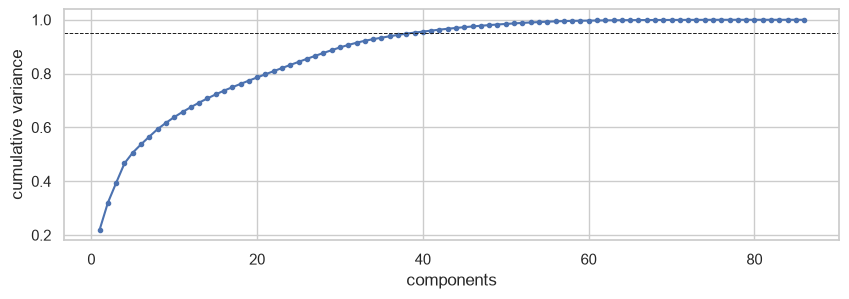

PCA-39 reconstruction baseline: ROC-AUC=0.660  PR-AUC=0.241  (prevalence 0.058)


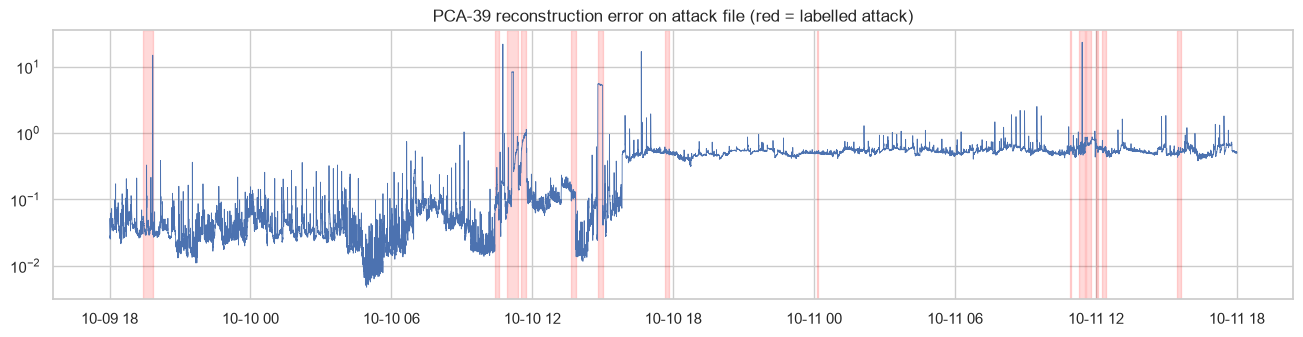

PC1 -> ['TOTAL_CONS_REQUIRED_FLOW', '2_FIT_003_PV', '2_P_003_SPEED', '2_P_003_STATUS', '2_PIT_002_PV', '2_MV_006_STATUS']
PC2 -> ['2_FIT_002_PV', '3_AIT_005_PV', '3_FIT_001_PV', '2_P_004_SPEED', '3_AIT_002_PV', '2_PIT_003_PV']
PC3 -> ['2_FIC_401_PV', '2_FQ_401_PV', '2_FIC_101_PV', '2_FQ_101_PV', '2_MCV_601_CO', '2_MCV_301_CO']
PC4 -> ['2A_AIT_001_PV', '1_AIT_001_PV', '1_AIT_003_PV', '2B_AIT_001_PV', '2B_AIT_003_PV', '2B_AIT_004_PV']


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score

scaler = StandardScaler().fit(n_rs[MODEL_FEATURES])
Xn = scaler.transform(n_rs[MODEL_FEATURES]); Xa = scaler.transform(a_rs[MODEL_FEATURES])
Xa = np.clip(Xa, -50, 50)            # constant-ish sensors can explode z-scores

pca_full = PCA().fit(Xn)
cum = np.cumsum(pca_full.explained_variance_ratio_)
for t in (.9, .95, .99):
    print(f"{t:.0%} variance -> {np.searchsorted(cum, t) + 1} components (of {len(MODEL_FEATURES)})")
plt.figure(figsize=(10, 3)); plt.plot(np.arange(1, len(cum) + 1), cum, marker=".")
plt.axhline(.95, ls="--", c="k", lw=.7); plt.xlabel("components"); plt.ylabel("cumulative variance"); plt.show()

k = int(np.searchsorted(cum, .95) + 1)
pca = PCA(k).fit(Xn)
recon = pca.inverse_transform(pca.transform(Xa))
err_per_sensor = pd.DataFrame((Xa - recon) ** 2, index=a_rs.index, columns=MODEL_FEATURES)
score = err_per_sensor.mean(axis=1)
y = a_rs.ATTACK.astype(int)
print(f"PCA-{k} reconstruction baseline: ROC-AUC={roc_auc_score(y, score):.3f}  PR-AUC={average_precision_score(y, score):.3f}  (prevalence {y.mean():.3f})")

fig, ax = plt.subplots(figsize=(16, 3.5))
ax.plot(score.index, score, lw=.6); ax.set_yscale("log")
for _, r in SEG.iterrows(): ax.axvspan(r.start, r.end, color="red", alpha=.15)
ax.set_title(f"PCA-{k} reconstruction error on attack file (red = labelled attack)"); plt.show()

# loadings: which sensors define the main modes of variation
load = pd.DataFrame(pca.components_[:4].T, index=MODEL_FEATURES, columns=[f"PC{i+1}" for i in range(4)])
for pc in load:
    print(pc, "->", load[pc].abs().sort_values(ascending=False).index[:6].tolist())

## I. Attack catalogue: which sensors each attack touches
For every labelled attack segment, each sensor is scored two ways: (1) its mean against the normal file, and (2) the **jump** from the 10 minutes before the attack to the attack window, scaled by how large such 10-minute jumps normally are for that sensor. The second score is robust to the drift found in §8 and does not over-rate slowly wandering sensors. The top sensors per attack serve as ground truth for checking the LSTM-AE's per-sensor reconstruction errors, and as context for the OpenRouter/LLM explanation prompt. The table is saved to `wadi_attack_catalogue.csv`.

In [ ]:
mu, sd = normal_df[MODEL_FEATURES].mean(), normal_df[MODEL_FEATURES].std().replace(0, np.nan)
# normal size of a "10 min before -> next 10 min" change in the mean, per sensor
_w = int(pd.Timedelta("10min") / pd.Timedelta(RESAMPLE))
_roll = n_rs[MODEL_FEATURES].rolling(_w).mean()
jump_sd = (_roll.shift(-_w) - _roll).std().replace(0, np.nan)
cat_rows = []
for name, r in SEG.iterrows():
    seg = attack_df.loc[r.start:r.end, MODEL_FEATURES]
    pre = attack_df.loc[r.start - pd.Timedelta("10min"): r.start - pd.Timedelta("1s"), MODEL_FEATURES]
    z_global = ((seg.mean() - mu) / sd).abs()
    z_local = ((seg.mean() - pre.mean()) / jump_sd).abs()
    top_local = z_local.replace([np.inf], np.nan).dropna().sort_values(ascending=False).head(5)
    pca_seg = err_per_sensor.loc[r.start:r.end].mean().sort_values(ascending=False).head(5)
    cat_rows.append({"attack": name, "start": r.start, "duration_min": r.duration_s / 60,
                     "stages": sorted({tax.loc[s, "stage"] for s in top_local.index}),
                     "top_sensors_vs_pre10min": ", ".join(f"{s}({v:.1f})" for s, v in top_local.items()),
                     "top_sensors_vs_normalfile": ", ".join(z_global.dropna().sort_values(ascending=False).head(3).index),
                     "top_PCA_recon_sensors": ", ".join(pca_seg.index[:3]),
                     "actuators_changed": SEG.loc[name, "actuators_changed_vs_10min_before"],
                     "constant_tags_changed": [c for c in const_but_attacked
                                               if attack_df.loc[r.start:r.end, c].nunique() > 1
                                               or attack_df.loc[r.start:r.end, c].iloc[0] != normal_df[c].iloc[0]]})
catalogue = pd.DataFrame(cat_rows).set_index("attack")
pd.set_option("display.max_colwidth", 120)
display(catalogue)
catalogue.to_csv("wadi_attack_catalogue.csv")

,start,duration_min,stages,top_sensors_vs_pre10min,top_sensors_vs_normalfile,top_PCA_recon_sensors,actuators_changed,constant_tags_changed
attack,,,,,,,,
A1,2017-10-09 19:25:03,25.016667,[1],"1_FIT_001_PV(3.0), 1_P_001_STATUS(3.0), 1_P_003_STATUS(3.0), 1_MV_001_STATUS(3.0), 1_AIT_004_PV(2.6)","2B_AIT_004_PV, 1_AIT_004_PV, 2A_AIT_004_PV","3_AIT_002_PV, 3_FIT_001_PV, 2B_AIT_003_PV","[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STATUS]",[]
A2,2017-10-10 10:24:13,9.850000,[2],"2_MCV_301_CO(5.6), 2_LS_101_AL(4.0), 2_LS_401_AL(3.6), 2_MV_401_STATUS(3.4), 2_FQ_401_PV(3.0)","2_MCV_301_CO, 2B_AIT_004_PV, 2A_AIT_004_PV","1_MV_001_STATUS, 2_MCV_301_CO, 1_FIT_001_PV","[1_P_001_STATUS, 1_P_003_STATUS, 2_MV_401_STATUS]",[]
A3,2017-10-10 10:55:03,29.016667,"[1, 2]","1_AIT_001_PV(64.6), 2_PIT_001_PV(7.1), 2_PIT_002_PV(5.3), 2_DPIT_001_PV(5.3), 2_FQ_201_PV(5.2)","2_PIT_001_PV, 1_AIT_001_PV, 2_FQ_501_PV","1_AIT_001_PV, 2B_AIT_001_PV, 2A_AIT_001_PV","[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STATUS, 2_MV_201_STATUS]","[1_MV_002_STATUS, 1_MV_003_STATUS]"
A4,2017-10-10 11:30:43,14.183333,"[2, plant]","LEAK_DIFF_PRESSURE(11.2), 2_PIT_002_PV(10.9), 2_DPIT_001_PV(10.6), 2_FIT_003_PV(9.6), 2_MCV_401_CO(8.4)","2_LT_002_PV, 2_PIT_001_PV, 2_MCV_201_CO","2_FIT_002_PV, 2_MCV_401_CO, 2_MCV_301_CO","[2_MV_006_STATUS, 2_MV_301_STATUS, 2_P_003_STATUS]",[]
A5,2017-10-10 13:39:33,11.183333,"[2, 2B]","2B_AIT_001_PV(6.7), 2_PIC_003_CO(6.3), 2_PIT_003_PV(5.2), 2_PIC_003_PV(5.2), 2_FQ_201_PV(3.9)","2A_AIT_004_PV, 2B_AIT_004_PV, 3_LT_001_PV","2_FIT_002_PV, 2_MCV_501_CO, 3_LT_001_PV",[],[]
A6,2017-10-10 14:48:20,11.650000,[1],"1_AIT_002_PV(218.1), 1_AIT_001_PV(2.5), 1_FIT_001_PV(2.0), 1_P_001_STATUS(2.0), 1_P_003_STATUS(2.0)","1_AIT_002_PV, 2_MCV_301_CO, 2B_AIT_004_PV","2_LT_001_PV, 1_AIT_002_PV, 3_AIT_005_PV","[1_MV_001_STATUS, 1_P_001_STATUS, 1_P_003_STATUS, 1_P_005_STATUS, 2_MV_003_STATUS]","[1_MV_002_STATUS, 1_MV_003_STATUS]"
A7,2017-10-10 17:40:03,9.683333,"[2, 2A, 2B, 3]","2B_AIT_002_PV(34.1), 2_FIT_002_PV(1.3), 2A_AIT_001_PV(1.3), 3_LT_001_PV(0.7), 2_LT_001_PV(0.7)","2B_AIT_002_PV, 2B_AIT_004_PV, 2A_AIT_004_PV","2A_AIT_003_PV, 2_P_004_SPEED, 3_AIT_005_PV",[],[2_MCV_007_CO]
A8,2017-10-11 00:07:33,3.383333,"[2, 2A, 2B, 3]","2B_AIT_002_PV(175.7), 2A_AIT_004_PV(1.6), 3_AIT_004_PV(1.4), 3_LT_001_PV(0.9), 2_LT_001_PV(0.6)","2B_AIT_002_PV, 3_LT_001_PV, 1_LT_001_PV","2_P_004_SPEED, 2A_AIT_003_PV, 3_AIT_005_PV",[],[]
A9,2017-10-11 10:55:03,1.466667,"[2, 2B]","2B_AIT_002_PV(71.5), 2_MCV_501_CO(6.7), 2_LS_201_AL(4.6), 2_LS_501_AL(4.6), 2_MV_201_STATUS(3.4)","2B_AIT_002_PV, 2_MCV_501_CO, 2_FIT_001_PV","2A_AIT_003_PV, 2_P_004_SPEED, 2_FIC_201_CO","[1_MV_004_STATUS, 1_P_005_STATUS, 2_MV_003_STATUS, 2_MV_201_STATUS]",[1_P_006_STATUS]


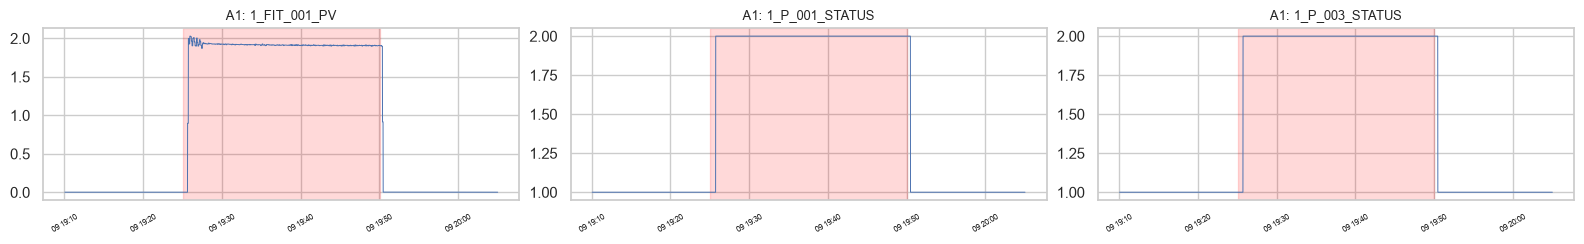

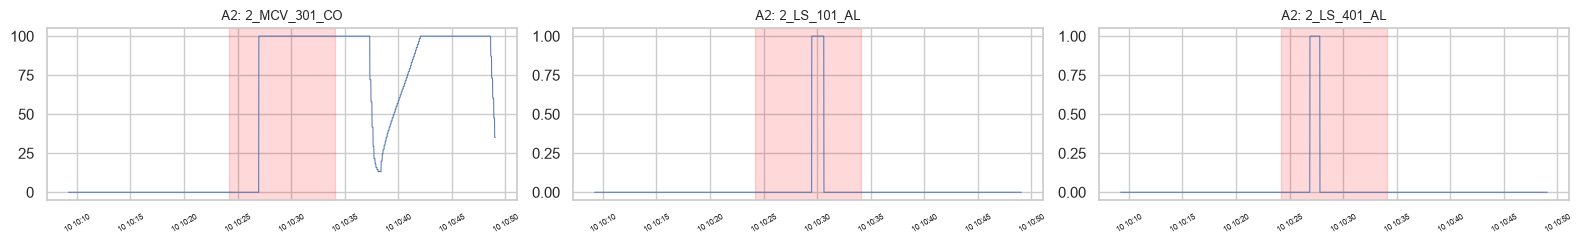

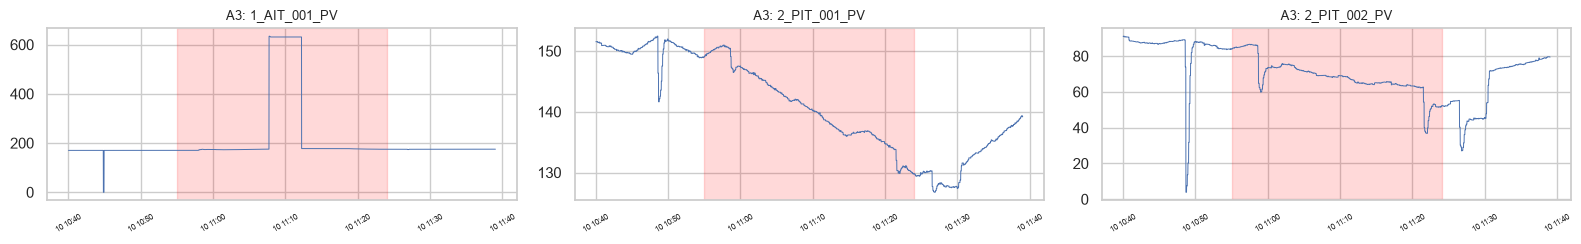

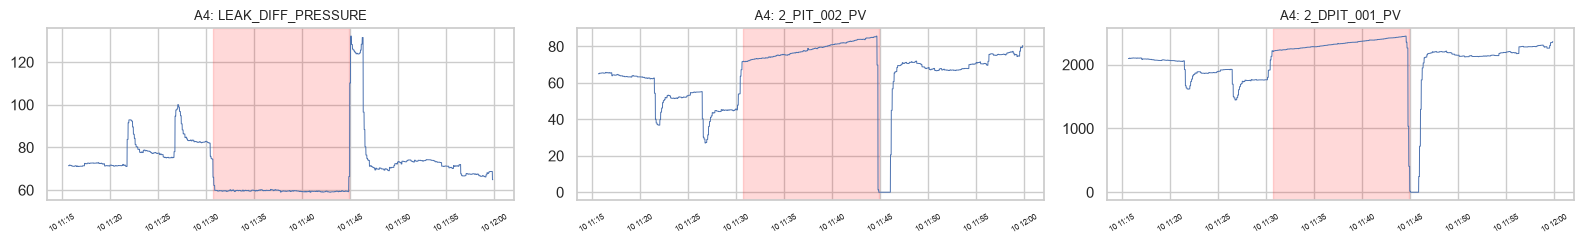

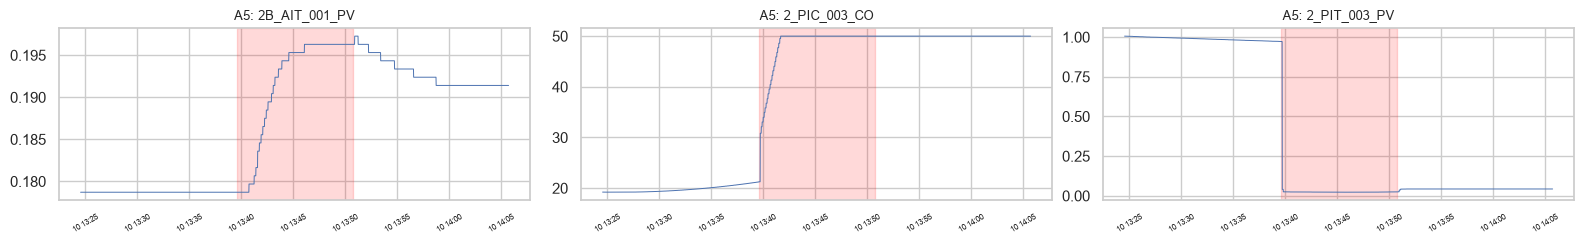

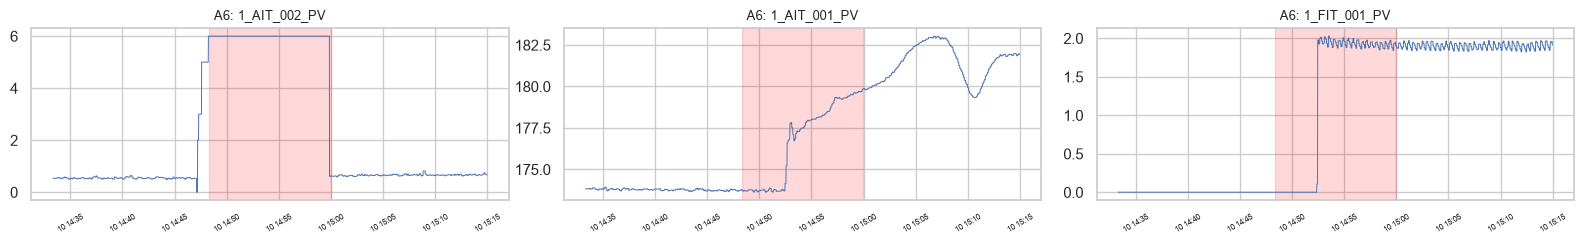

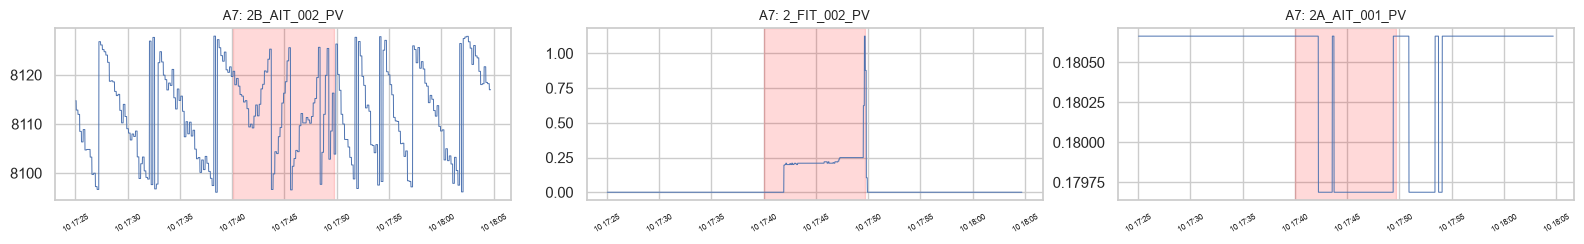

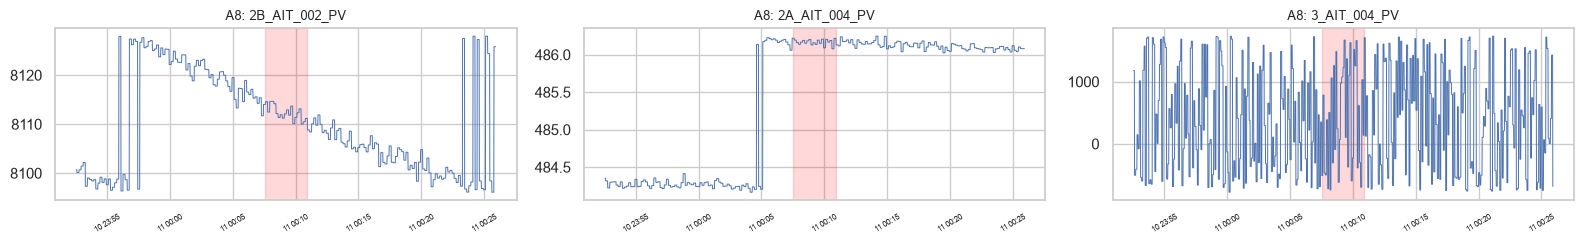

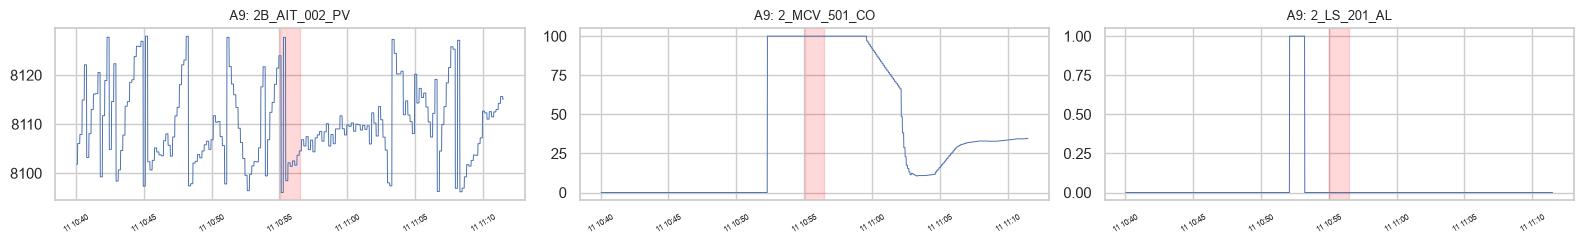

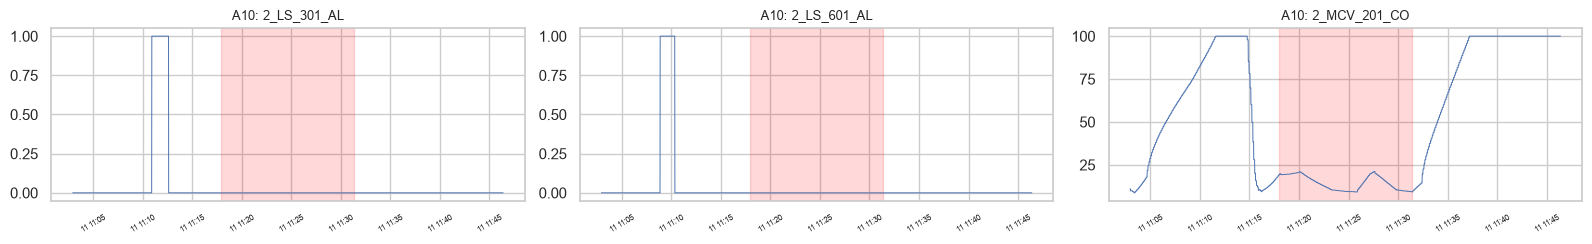

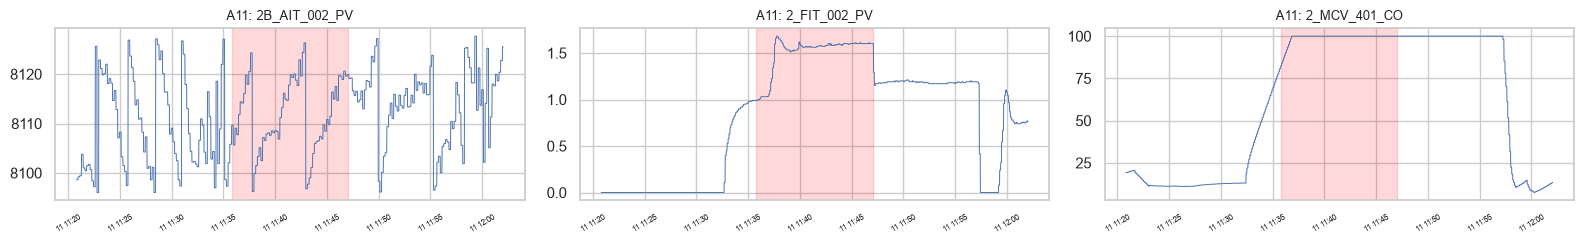

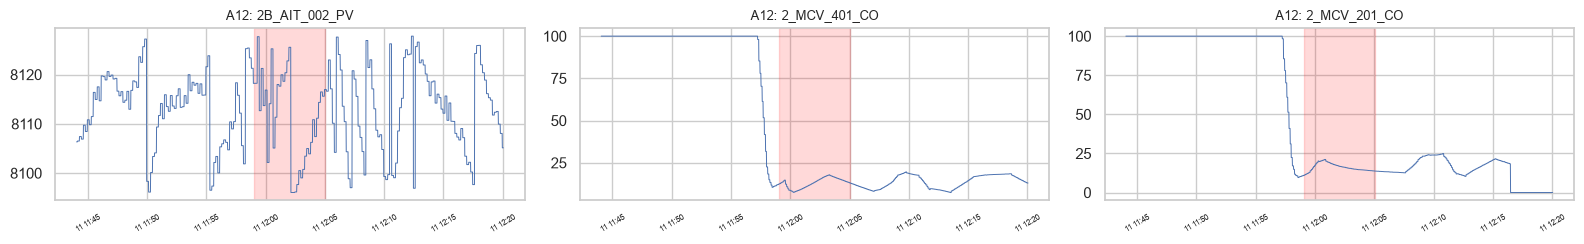

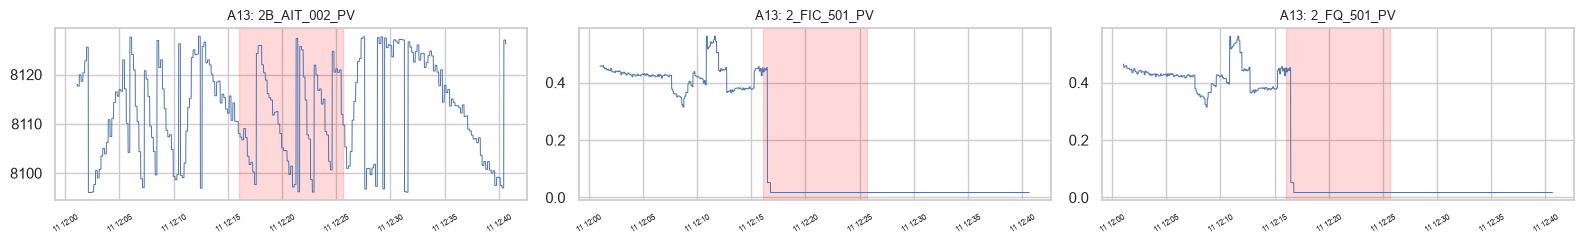

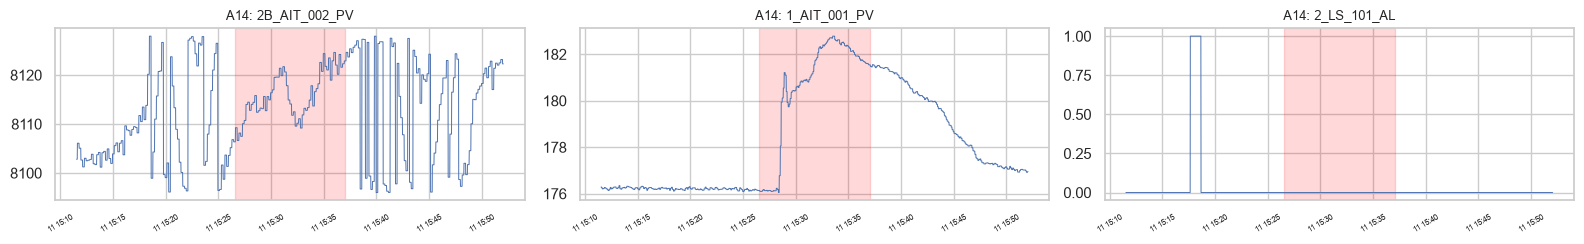

In [ ]:
# Zoom on each attack: top-3 sensors, 15 min before -> 15 min after
for name, r in SEG.iterrows():
    sensors = [s.split("(")[0] for s in catalogue.loc[name, "top_sensors_vs_pre10min"].split(", ")[:3]]
    w = attack_df.loc[r.start - pd.Timedelta("15min"): r.end + pd.Timedelta("15min"), sensors]
    fig, axes = plt.subplots(1, len(sensors), figsize=(16, 2.6))
    for ax, s in zip(np.atleast_1d(axes), sensors):
        ax.plot(w.index, w[s], lw=.7); ax.axvspan(r.start, r.end, color="red", alpha=.15)
        ax.set_title(f"{name}: {s}", fontsize=9); ax.tick_params(axis="x", labelsize=6, rotation=30)
    plt.tight_layout(); plt.show()

## J. Correlation breaks during attacks
Stealthy attacks keep each sensor inside its normal range but break **relationships**. Example: the PV is spoofed while the downstream pressure does not follow. For the strongest normal-data pairs, the cell compares correlation inside each attack window with the 30 minutes before it. A large drop means the attack decoupled two sensors that normally move together. This is exactly the kind of signal an LSTM-AE picks up and a per-sensor threshold misses.

,attack,pair,rho_normal,rho_pre30,rho_attack,drop
201,A14,2_MV_006_STATUS ~ 2_P_003_STATUS,0.913,0.724,0.012,0.712
165,A12,1_AIT_001_PV ~ 2B_AIT_001_PV,0.908,-0.744,0.033,0.711
41,A3,2_MCV_201_CO ~ 2_MV_501_STATUS,-0.925,-0.724,0.014,0.710
89,A6,2_FIT_003_PV ~ 2_MV_006_STATUS,0.881,0.744,-0.036,0.708
68,A4,2_PIT_002_PV ~ LEAK_DIFF_PRESSURE,-0.838,-0.846,-0.156,0.689
107,A9,2_FIC_201_PV ~ 2_FQ_201_PV,1.000,1.000,0.323,0.677
14,A1,1_AIT_001_PV ~ 2B_AIT_001_PV,0.908,-0.800,0.154,0.646
112,A9,1_AIT_001_PV ~ 2B_AIT_001_PV,0.908,-0.746,-0.123,0.623
77,A6,1_AIT_001_PV ~ 2A_AIT_001_PV,0.972,-0.652,0.069,0.583
64,A4,2_FIT_003_PV ~ 2_PIC_003_CO,-0.900,0.968,-0.391,0.577


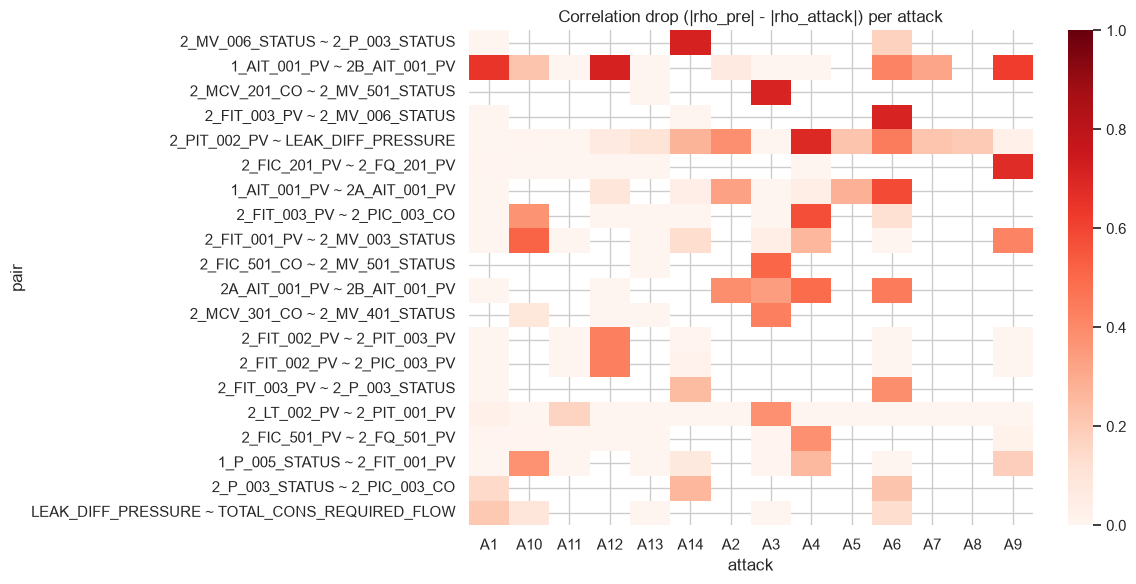

In [ ]:
strong = pairs[(pairs["abs"] > .8)].head(40)
brk = []
for name, r in SEG.iterrows():
    seg = attack_df.loc[r.start:r.end]
    pre = attack_df.loc[r.start - pd.Timedelta("30min"): r.start]
    for _, p in strong.iterrows():
        c_seg, c_pre = seg[p.a].corr(seg[p.b]), pre[p.a].corr(pre[p.b])
        if np.isfinite(c_seg) and np.isfinite(c_pre):
            brk.append({"attack": name, "pair": f"{p.a} ~ {p.b}", "rho_normal": p.rho,
                        "rho_pre30": c_pre, "rho_attack": c_seg, "drop": abs(c_pre) - abs(c_seg)})
brk = pd.DataFrame(brk)
if len(brk):
    worst = brk.sort_values("drop", ascending=False).groupby("attack").head(2)
    display(worst.round(3))
    piv = brk.pivot_table(index="pair", columns="attack", values="drop")
    piv = piv.loc[piv.max(axis=1).sort_values(ascending=False).index[:20]]
    plt.figure(figsize=(12, 6)); sns.heatmap(piv, cmap="Reds", vmin=0, vmax=1)
    plt.title("Correlation drop (|rho_pre| - |rho_attack|) per attack"); plt.tight_layout(); plt.show()

## K. Rolling statistics with attack overlay (improved v1 §14)

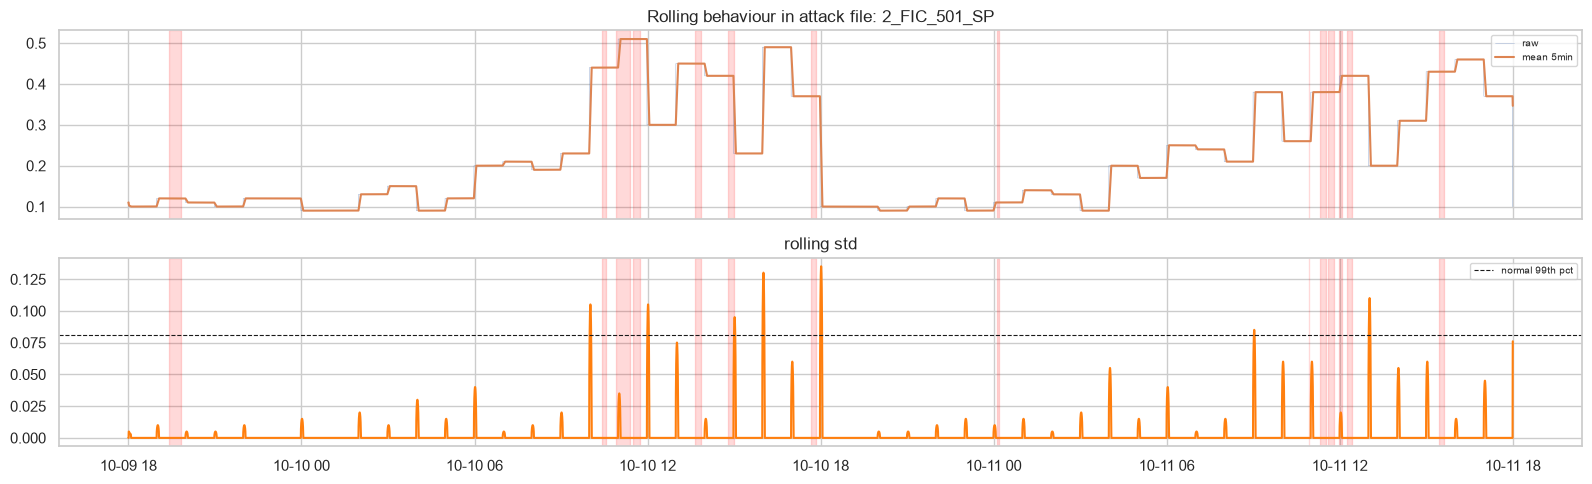

In [ ]:
ROLLING_SENSOR = top[0]
ROLLING_WINDOW = "5min"     # time-based window now that the index is a real timestamp
s = attack_df[ROLLING_SENSOR]
fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True)
axes[0].plot(s.index, s, lw=.4, alpha=.5, label="raw")
axes[0].plot(s.index, s.rolling(ROLLING_WINDOW).mean(), label=f"mean {ROLLING_WINDOW}")
axes[1].plot(s.index, s.rolling(ROLLING_WINDOW).std(), c="tab:orange")
ref = normal_df[ROLLING_SENSOR].rolling(ROLLING_WINDOW).std().quantile(.99)
axes[1].axhline(ref, ls="--", c="k", lw=.8, label="normal 99th pct")
for ax in axes:
    for _, r in SEG.iterrows(): ax.axvspan(r.start, r.end, color="red", alpha=.15)
    ax.legend(fontsize=7)
axes[0].set_title(f"Rolling behaviour in attack file: {ROLLING_SENSOR}"); axes[1].set_title("rolling std")
plt.tight_layout(); plt.show()

## L. Export: summaries plus a modelling config
`wadi_feature_config.json` holds the decisions made above so the Isolation Forest / LSTM-AE notebooks load the same feature list, groups and window hint, instead of re-deriving them.

In [ ]:
def make_sensor_summary(df, cols, name):
    s = df[cols].describe().T
    s["unique_values"] = df[cols].nunique()
    s.insert(0, "dataset", name)
    return s
summary = make_sensor_summary(normal_df, FEATURES, "normal").join(ks).join(tax)
summary["hod_strength"] = hod_strength
summary["acf_decay_s"] = decay
summary.to_csv("wadi_sensor_summary_v2.csv")

config = {
    "features": MODEL_FEATURES,
    "totalisers_use_diff_or_drop": TOTALISERS,
    "continuous": CONT, "discrete": DISC,
    "dropped_all_nan": all_nan,
    "dropped_constant_normal": const_normal,
    "constant_normal_but_attacked": const_but_attacked,
    "high_drift_sensors": ks.index[ks.KS_drift > .5].tolist(),
    "correlated_groups": {f"G{k}": v for k, v in groups.items()},
    "pca_components_95": int(k),
    "suggested_window_s": float(np.nanmax([decay.median(), lag_df["best_lag_s"].abs().max() if len(lag_df) else 0])),
    "resample": RESAMPLE,
    "label": "ATTACK (1=attack, 0=normal); original -1=attack, 1=normal",
}
Path("wadi_feature_config.json").write_text(json.dumps(config, indent=2, default=str))
print("Saved: wadi_sensor_summary_v2.csv, wadi_attack_catalogue.csv, wadi_feature_config.json")
print(json.dumps({k: (v if not isinstance(v, list) else f"{len(v)} items") for k, v in config.items() if k != "correlated_groups"}, indent=1))

Saved: wadi_sensor_summary_v2.csv, wadi_attack_catalogue.csv, wadi_feature_config.json
{
 "features": "86 items",
 "totalisers_use_diff_or_drop": "7 items",
 "continuous": "67 items",
 "discrete": "26 items",
 "dropped_all_nan": "4 items",
 "dropped_constant_normal": "30 items",
 "constant_normal_but_attacked": "5 items",
 "high_drift_sensors": "7 items",
 "pca_components_95": 39,
 "suggested_window_s": 1600.0,
 "resample": "10s",
 "label": "ATTACK (1=attack, 0=normal); original -1=attack, 1=normal"
}


## What to take into modelling
* **Train on the normal file only, and split it chronologically.** Hold out the last ~20% for threshold calibration.
* **Drop** the all-NaN and constant-in-normal sensors from the learned models, and difference or drop the totalisers (§6). Add a simple rule for `constant_normal_but_attacked`, because those tags changing at all is an alarm.
* **Drift (§8):** sensors with high `KS_drift` will produce false positives. Options: per-file re-standardisation, a short warm-up adaptation, or excluding them from the score, but report which choice you made.
* **Window length:** use at least the larger of the ACF decay and the longest lead/lag (§D/E) at your sampling rate.
* **Explanations for operators:** send the LLM the per-sensor reconstruction errors *plus* the context computed here (stage, loop PV−SP error, actuator links, broken correlations, unseen actuator mode). The attack catalogue (§I) gives ground truth to check whether the explanations name the right sensors.